# Energy prices and inflation — v2: all data from FRED

**An updated application of Kilian and Zhou (2022), _A Broader Perspective on the Inflationary Effects of Energy Price Shocks_.**

This standalone notebook recreates the analyses in Figures 1–10 and Tables 2–3 using only live FRED API downloads. Separate seven-variable CPI and PCE systems each have baseline and cointegration specifications. Run all cells in order with an internet connection. Saved outputs describe this execution; each rerun downloads fresh data.

**What changes from v1.** Gasoline and the four inflation indexes retain their definitions. Diesel is averaged from FRED's weekly U.S. retail observations. Jet fuel and natural gas use spot prices throughout, without splicing. Household electricity replaces EIA's all-sector electricity price. Henry Hub spot history begins in January 1997, so growth rates start in February 1997 and estimation starts in August 1997 after six lags. These measurement and sample changes can affect estimates; this is a simpler FRED application, not an exact reproduction of the paper or v1.

**Latest data.** Each CPI/PCE system uses its own latest complete month. Baseline and cointegration use identical dates within each inflation measure. Set `MATCH_ENDPOINTS = True` below to rerun all four models on a common endpoint for a more controlled comparison. No missing endpoint is forecast. Sections 1–3 document data; sections 4–5 explain and validate methods; sections 6–7 present results; section 8 compares CPI and PCE with their sample dates shown.

The model, priors, 10,000 accepted stationary draws, joint response inference, and table conventions follow v1. Identified energy shocks are innovations under recursive assumptions, not separately identified physical supply shocks. The original notebook remains unchanged.


Section 9 translates the March–July 2026 energy shocks into their contribution to July 2026 year-over-year core PCE inflation, using the exact downloaded index ratio.

Section 10 reports five-panel IRFs for separate 10% initial increases in all five energy prices, with headline/core CPI and PCE versions under both specifications.

Section 11 projects the March–July 2026 energy contribution to core PCE y/y inflation through December, with Figure 13 and posterior peak estimates.

## 1. Setup and configuration
Uncomment the installation command if needed, then restart the kernel. No local input or EIA API key is required. The supplied FRED key is included as requested and is never printed by the notebook; remove it before sharing publicly.


In [1]:
# Uncomment once if needed, then restart the kernel.
# %pip install numpy pandas scipy statsmodels requests matplotlib threadpoolctl ipykernel

In [2]:
import time
import importlib.metadata as metadata
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import display, Markdown
from scipy import linalg, stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.api import VAR
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from threadpoolctl import threadpool_limits

# Small VAR matrices run faster without BLAS thread oversubscription.
blas_limit = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 30)

FRED_API_KEY = "51f3ac7bc8b65cb6bb2589fc570292be"
REQUESTED_START = pd.Timestamp("1995-02-01")
MATCH_ENDPOINTS = False  # True: fit CPI and PCE through the same latest complete month.
HISTORY_START = pd.Timestamp("2019-06-01")
P = 6
DRAWS = 10_000
IRF_HORIZON = 18
CREDIBLE_MASS = 0.68
BASE_SEED = 2224
BATCH_SIZE = 250
ENERGY = ["Gasoline", "Diesel", "Jet fuel", "Natural gas", "Electricity"]
ORDER = ENERGY + ["Headline", "Core"]
COLORS = {"CPI": "#245a81", "PCE": "#ab5626"}

packages = ["numpy", "pandas", "scipy", "statsmodels", "requests", "matplotlib",
            "threadpoolctl", "ipykernel"]
display(pd.Series({p: metadata.version(p) for p in packages}, name="Installed version").to_frame())

,Installed version
numpy,2.3.5
pandas,3.0.1
scipy,1.18.1
statsmodels,0.15.0
requests,2.34.2
matplotlib,3.11.2
threadpoolctl,3.6.0
ipykernel,7.3.0


## 2. Live FRED sources and data preparation

FRED is the retrieval source for every observation; underlying producers remain BLS, BEA, and EIA. Links and live metadata below identify units, seasonal adjustment, release update times, and available dates.

| Input | FRED series | Definition and difference from v1 |
|---|---|---|
| Headline / core CPI | [CPIAUCSL](https://fred.stlouisfed.org/series/CPIAUCSL) / [CPILFESL](https://fred.stlouisfed.org/series/CPILFESL) | Supplied seasonally adjusted indexes; unchanged |
| Headline / core PCE | [PCEPI](https://fred.stlouisfed.org/series/PCEPI) / [PCEPILFE](https://fred.stlouisfed.org/series/PCEPILFE) | Supplied seasonally adjusted indexes; unchanged |
| Gasoline | [APU00007471A](https://fred.stlouisfed.org/series/APU00007471A) | All-types U.S. city-average retail dollars/gallon; unchanged, not a gasoline CPI index |
| Diesel | [GASDESW](https://fred.stlouisfed.org/series/GASDESW) | Weekly U.S. retail dollars/gallon, averaged over reported weekly dates within each completed calendar month |
| Jet fuel | [MJFUELUSGULF](https://fred.stlouisfed.org/series/MJFUELUSGULF) | Gulf Coast spot dollars/gallon for the entire sample; replaces refiner prices and their continuation |
| Natural gas | [MHHNGSP](https://fred.stlouisfed.org/series/MHHNGSP) | Henry Hub spot dollars/million Btu for the entire sample; replaces contract-1 futures and their continuation |
| Electricity | [APU000072610](https://fred.stlouisfed.org/series/APU000072610) | Household U.S. city-average dollars/kWh; replaces all-sector electricity |

**Frequency and timing.** We average weekly diesel observations ourselves, rather than use FRED's `GASDESM`, which is labeled end-of-period. Each complete month's scheduled weekly observations must be present; the current incomplete calendar month is excluded. This equal-weight average over weekly survey dates need not exactly equal EIA's monthly aggregation. All other series are already monthly. No series is spliced or backfilled before its history begins.

**Missing October 2025.** Headline CPI, core CPI, gasoline, and (new in v2) electricity are eligible for `sqrt(September × November)` only if October is missing. Published observations are preserved. Every interpolation is audited. Other internal gaps raise an error.

**Seasonality and measurement.** Inflation retains its supplied seasonal adjustment. Electricity is adjusted in logs using robust STL with period 12 and seasonal window 13, separately through each model's endpoint. Other energy prices retain their unadjusted data, as in v1. BLS average prices reflect the sampled mix of purchases; they are not fixed-basket CPI subindexes. Household electricity also narrows the coverage relative to the paper. Natural-gas spot prices can be more volatile than futures prices, so response differences can reflect the changed shock measure.


In [3]:
session = requests.Session()
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])))
session.headers.update({"User-Agent": "EnergyInflationResearchNotebook/2.0"})
run_time = datetime.now(timezone.utc)
last_complete_month = pd.Timestamp(run_time.date()).to_period("M").to_timestamp() - pd.offsets.MonthBegin()

def fred_json(endpoint, **parameters):
    # Errors omit keyed URLs and response bodies.
    try:
        response = session.get(f"https://api.stlouisfed.org/fred/{endpoint}", params={
            "api_key": FRED_API_KEY, "file_type": "json", **parameters}, timeout=60)
        response.raise_for_status()
        return response.json()
    except (requests.RequestException, ValueError):
        raise RuntimeError(f"FRED request failed for {parameters.get('series_id')}; check access and credentials.") from None

fred_ids = {"Headline CPI": "CPIAUCSL", "Core CPI": "CPILFESL",
            "Headline PCE": "PCEPI", "Core PCE": "PCEPILFE",
            "Gasoline": "APU00007471A", "Diesel": "GASDESW",
            "Jet fuel": "MJFUELUSGULF", "Natural gas": "MHHNGSP",
            "Electricity": "APU000072610"}
raw, source_rows, diesel_audit = {}, [], None
for name, series_id in fred_ids.items():
    info = fred_json("series", series_id=series_id)["seriess"][0]
    records = fred_json("series/observations", series_id=series_id,
                       observation_start="1994-01-01")["observations"]
    frame = pd.DataFrame(records)
    series = pd.Series(pd.to_numeric(frame["value"], errors="coerce").to_numpy(),
                       index=pd.to_datetime(frame["date"]), name=name).sort_index()
    assert series.index.is_unique
    if name == "Diesel":
        # FRED GASDESW is dated every Monday; missing survey weeks must not be silently omitted.
        assert info["frequency_short"] == "W"
        assert (series.index.dayofweek == 0).all()
        weekly_dates = pd.date_range(series.index.min(),
                                    last_complete_month + pd.offsets.MonthEnd(), freq="W-MON")
        weekly = series.reindex(weekly_dates)
        if weekly.isna().any():
            raise ValueError(f"Missing diesel survey weeks: {weekly[weekly.isna()].index.tolist()}")
        monthly = weekly.resample("MS").mean()
        counts = weekly.resample("MS").count()
        diesel_audit = pd.DataFrame({"Weekly observations": counts, "Monthly mean ($/gallon)": monthly})
        # The first survey month may be partial, but is earlier than any model's start.
        assert counts.iloc[1:].between(4, 5).all()
    else:
        assert info["frequency_short"] == "M" and (series.index.day == 1).all()
        monthly = series.loc[:last_complete_month]
    raw[name] = monthly
    source_rows.append({"Input": name, "FRED code": series_id, "Title": info["title"],
        "Units": info["units"], "Source frequency": info["frequency"],
        "Seasonal adjustment": info["seasonal_adjustment"], "FRED last updated": info["last_updated"],
        "FRED history starts": info["observation_start"], "First downloaded valid month": monthly.first_valid_index(),
        "Latest complete valid month": monthly.last_valid_index(), "Missing monthly rows": int(monthly.isna().sum()),
        "Source link": f"https://fred.stlouisfed.org/series/{series_id}"})

retrieved_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
availability = pd.DataFrame(source_rows).set_index("Input")
display(Markdown(f"**Retrieved:** {retrieved_at}. **Last completed calendar month:** {last_complete_month:%B %Y}."))
display(availability[["FRED code", "Units", "Source frequency", "Seasonal adjustment"]])
display(availability[["FRED history starts", "First downloaded valid month", "Latest complete valid month", "FRED last updated", "Missing monthly rows"]])
display(Markdown("**Recent diesel aggregation audit** (equal-weight mean over survey dates):"))
display(diesel_audit.tail(14))


**Retrieved:** 2026-09-13T23:18:21+00:00. **Last completed calendar month:** August 2026.

,FRED code,Units,Source frequency,Seasonal adjustment
Input,,,,
Headline CPI,CPIAUCSL,Index 1982-1984=100,Monthly,Seasonally Adjusted
Core CPI,CPILFESL,Index 1982-1984=100,Monthly,Seasonally Adjusted
Headline PCE,PCEPI,Index 2017=100,Monthly,Seasonally Adjusted
Core PCE,PCEPILFE,Index 2017=100,Monthly,Seasonally Adjusted
Gasoline,APU00007471A,U.S. Dollars,Monthly,Not Seasonally Adjusted
Diesel,GASDESW,Dollars per Gallon,"Weekly, Ending Monday",Not Seasonally Adjusted
Jet fuel,MJFUELUSGULF,Dollars per Gallon,Monthly,Not Seasonally Adjusted
Natural gas,MHHNGSP,Dollars per Million BTU,Monthly,Not Seasonally Adjusted
Electricity,APU000072610,U.S. Dollars,Monthly,Not Seasonally Adjusted


,FRED history starts,First downloaded valid month,Latest complete valid month,FRED last updated,Missing monthly rows
Input,,,,,
Headline CPI,1947-01-01,1994-01-01,2026-08-01,2026-09-11 08:37:49-05,1
Core CPI,1957-01-01,1994-01-01,2026-08-01,2026-09-11 08:37:53-05,1
Headline PCE,1959-01-01,1994-01-01,2026-07-01,2026-08-26 07:43:48-05,0
Core PCE,1959-01-01,1994-01-01,2026-07-01,2026-08-26 07:43:44-05,0
Gasoline,1978-01-01,1994-01-01,2026-08-01,2026-09-11 07:36:00-05,1
Diesel,1994-03-21,1994-03-01,2026-08-01,2026-09-09 09:04:05-05,0
Jet fuel,1990-04-01,1994-01-01,2026-08-01,2026-09-02 12:17:31-05,0
Natural gas,1997-01-01,1997-01-01,2026-08-01,2026-09-02 12:32:25-05,0
Electricity,1978-11-01,1994-01-01,2026-08-01,2026-09-11 07:35:41-05,1


**Recent diesel aggregation audit** (equal-weight mean over survey dates):

,Weekly observations,Monthly mean ($/gallon)
2025-07-01,4,3.77850
2025-08-01,4,3.74375
2025-09-01,5,3.74840
2025-10-01,4,3.67850
2025-11-01,4,3.82225
2025-12-01,5,3.61480
2026-01-01,4,3.52250
2026-02-01,4,3.72225
2026-03-01,5,4.92060
2026-04-01,4,5.50125


In [4]:
interpolation_audit = []

def fill_shutdown(series, name):
    result = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq="MS")).copy()
    target = pd.Timestamp("2025-10-01")
    if target in result.index and pd.isna(result.loc[target]):
        before, after = result.loc["2025-09-01"], result.loc["2025-11-01"]
        assert np.isfinite(before) and np.isfinite(after) and before > 0 and after > 0
        value = np.sqrt(before * after)
        result.loc[target] = value
        interpolation_audit.append({"Series": name, "Month": target.date(),
            "September": before, "November": after, "Interpolated October": value})
        np.testing.assert_allclose(value, np.sqrt(before * after), rtol=0, atol=0)
    # Preserve every published value, including any published October observation.
    published = series.dropna()
    np.testing.assert_array_equal(result.loc[published.index], published)
    return result

levels = {name: s.copy() for name, s in raw.items()}
for name in ["Headline CPI", "Core CPI", "Gasoline", "Electricity"]:
    levels[name] = fill_shutdown(levels[name], name)

level_start = max(REQUESTED_START - pd.offsets.MonthBegin(),
                  max(s.first_valid_index() for s in levels.values()))
START = level_start + pd.offsets.MonthBegin()
energy_end = min(levels[name].last_valid_index() for name in ENERGY)
endpoints = {measure: min(energy_end, levels[f"Headline {measure}"].last_valid_index(),
                         levels[f"Core {measure}"].last_valid_index()) for measure in ["CPI", "PCE"]}
if MATCH_ENDPOINTS:
    endpoints = dict.fromkeys(endpoints, min(endpoints.values()))

def prepare_prices(names, endpoint):
    dates = pd.date_range(level_start, endpoint, freq="MS")
    prices = pd.DataFrame({name: levels[name].reindex(dates) for name in names})
    missing = prices.isna().stack()
    if missing.any():
        raise ValueError(f"Unresolved internal gaps: {missing[missing].index.tolist()}")
    assert prices.index.is_unique and np.isfinite(prices.to_numpy()).all() and (prices > 0).all().all()
    adjusted = prices.copy()
    fit = STL(np.log(prices["Electricity"]), period=12, seasonal=13, robust=True).fit()
    adjusted["Electricity"] = np.exp(np.log(prices["Electricity"]) - fit.seasonal)
    rates = (100 * np.log(adjusted).diff()).iloc[1:]
    assert not rates.isna().any().any()
    return prices, rates

# Descriptive energy panel uses all complete energy months.
_, energy_growth = prepare_prices(ENERGY, energy_end)
models, model_growth, sample_rows = {}, {}, []
for measure in ["CPI", "PCE"]:
    endpoint = endpoints[measure]
    prices, rates = prepare_prices(ENERGY + [f"Headline {measure}", f"Core {measure}"], endpoint)
    model_growth[measure] = rates
    for specification in ["Baseline", "Cointegration"]:
        frame = rates.copy()
        frame.columns = ORDER
        if specification == "Cointegration":
            for name in ["Diesel", "Jet fuel"]:
                frame[name] = (100 * np.log(prices[name] / prices["Gasoline"])).reindex(frame.index)
        assert frame.index.equals(pd.date_range(START, endpoint, freq="MS"))
        assert np.isfinite(frame.to_numpy()).all()
        models[(specification, measure)] = frame
        sample_rows.append({"Model": specification, "Measure": measure, "Transformed start": frame.index[0],
            "Estimation start": frame.index[P], "Endpoint": frame.index[-1], "Estimation observations": len(frame)-P})
    assert models[("Baseline", measure)].index.equals(models[("Cointegration", measure)].index)
if MATCH_ENDPOINTS:
    assert models[("Baseline", "CPI")].index.equals(models[("Baseline", "PCE")].index)
display(pd.DataFrame(interpolation_audit) if interpolation_audit else Markdown("No shutdown interpolations needed."))
display(pd.DataFrame(sample_rows))
display(Markdown(f"**No splices or extrapolation.** Monthly rates begin {START:%B %Y}. "
    f"CPI ends **{endpoints['CPI']:%B %Y}**; PCE ends **{endpoints['PCE']:%B %Y}**. "
    "Electricity STL is fitted separately through each model endpoint; estimates can change on rerun."))


,Series,Month,September,November,Interpolated October
0,Headline CPI,2025-10-01,324.245,325.063,324.653742
1,Core CPI,2025-10-01,330.418,331.043,330.730352
2,Gasoline,2025-10-01,3.481,3.373,3.426575
3,Electricity,2025-10-01,0.188,0.189,0.188499


,Model,Measure,Transformed start,Estimation start,Endpoint,Estimation observations
0,Baseline,CPI,1997-02-01,1997-08-01,2026-08-01,349
1,Cointegration,CPI,1997-02-01,1997-08-01,2026-08-01,349
2,Baseline,PCE,1997-02-01,1997-08-01,2026-07-01,348
3,Cointegration,PCE,1997-02-01,1997-08-01,2026-07-01,348


**No splices or extrapolation.** Monthly rates begin February 1997. CPI ends **August 2026**; PCE ends **July 2026**. Electricity STL is fitted separately through each model endpoint; estimates can change on rerun.

## 3. Descriptive evidence — Figures 1 and 2
These plots use demeaned **monthly log growth in percentage points**, as in the paper's descriptive figures. Demeaning is for these plots only; the models include intercepts and use the undemeaned data. Figure 1 is shared by the CPI and PCE systems.

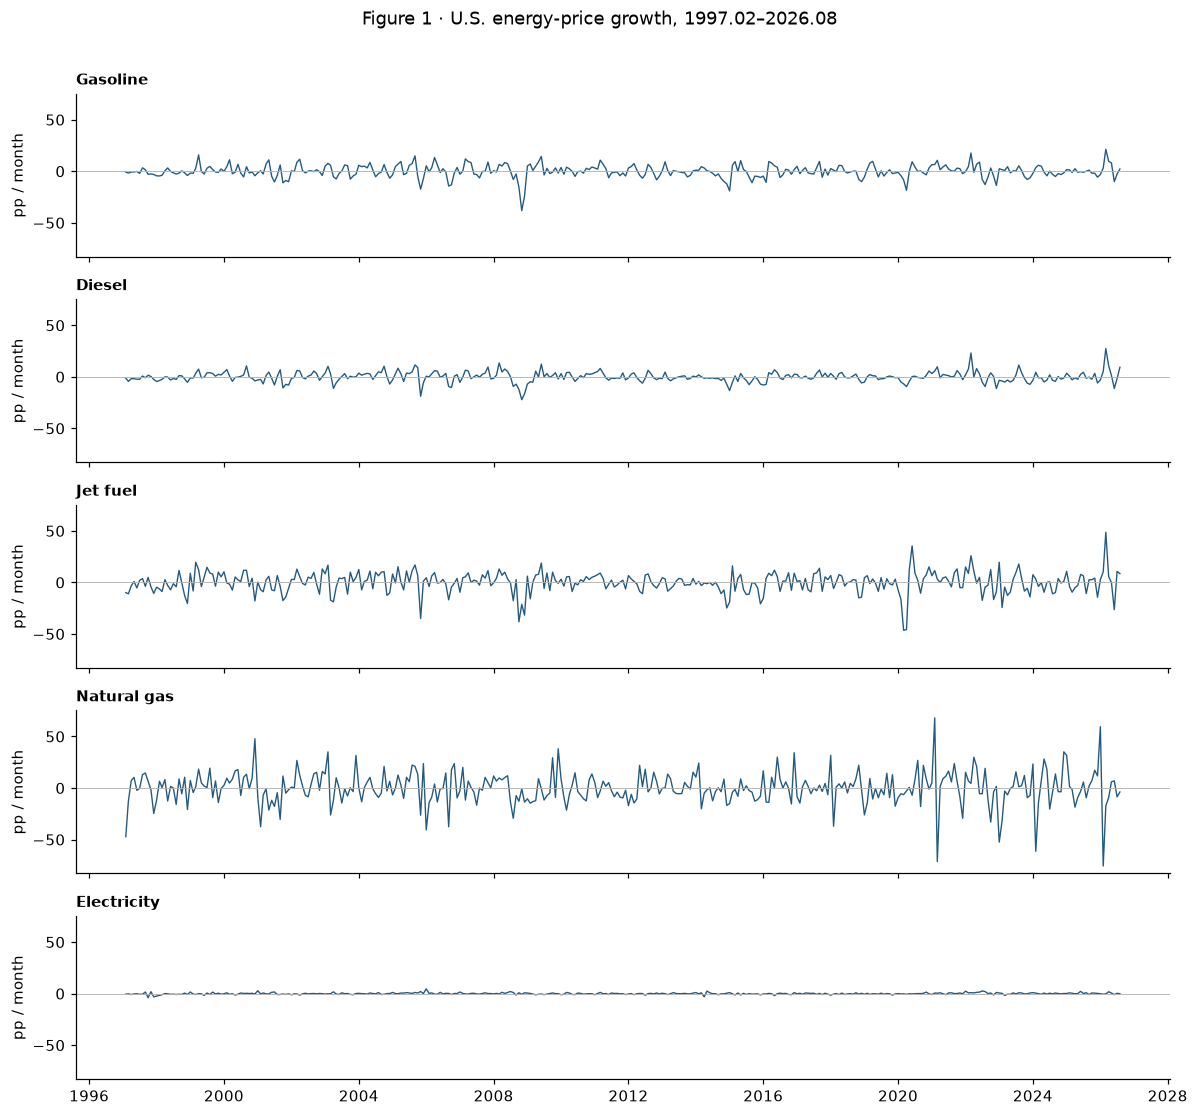

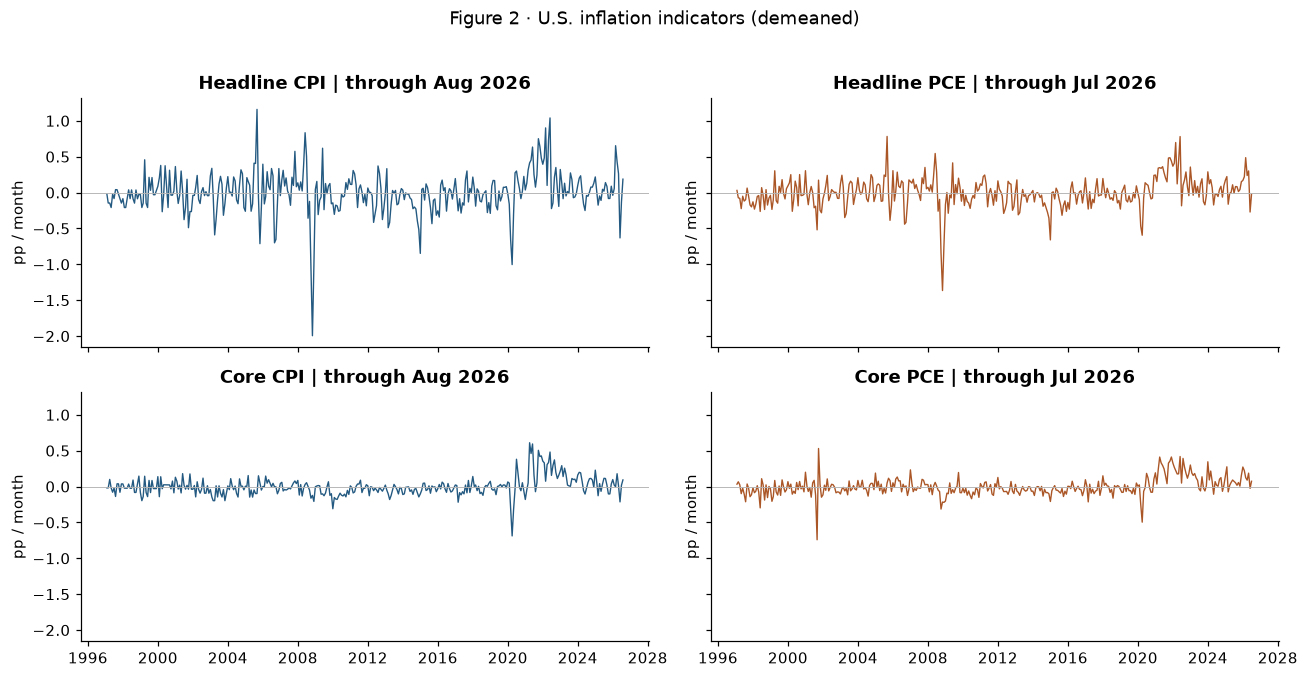

In [5]:
fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True, sharey=True)
for ax, name in zip(axes, ENERGY):
    series = energy_growth[name] - energy_growth[name].mean()
    ax.plot(series.index, series, color="#245a81", linewidth=0.9)
    ax.axhline(0, color="0.7", linewidth=0.6)
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_ylabel("pp / month")
fig.suptitle(f"Figure 1 · U.S. energy-price growth, {START:%Y.%m}–{energy_end:%Y.%m}", y=1.01)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, sharey=True)
for col, measure in enumerate(["CPI", "PCE"]):
    for row, kind in enumerate(["Headline", "Core"]):
        s = model_growth[measure][f"{kind} {measure}"]
        axes[row, col].plot(s.index, s - s.mean(), color=COLORS[measure], linewidth=0.9)
        axes[row, col].axhline(0, color="0.7", linewidth=0.6)
        axes[row, col].set_title(f"{kind} {measure} | through {endpoints[measure]:%b %Y}")
        axes[row, col].set_ylabel("pp / month")
fig.suptitle("Figure 2 · U.S. inflation indicators (demeaned)", y=1.02)
fig.tight_layout()
plt.show()

## 4. Bayesian VAR and structural calculations

For each system, $Y=XB+U$, with rows of $X$ containing an intercept followed by six lags, and $U_t\sim N(0,\Sigma)$. The prior is

$$B\mid\Sigma\sim MN(B_0,V_0,\Sigma),\qquad \Sigma\sim IW(S_0,\nu_0).$$

$B_0=0$, $\nu_0=9$, and $S_0=(9-7-1)\operatorname{diag}(s_1^2,\ldots,s_7^2)$, where $s_j^2$ is the residual variance from an AR(1) with intercept fitted to model variable $j$. The lag-$\ell$ prior row variance is $(0.2/\ell)^2/s_j^2$. The intercept row variance is $10^6$ (an explicit diffuse-prior convention). The cointegration specification uses the same prior rule on its transformed variables; it is a stationary VAR in growth rates and log price spreads, not an unrestricted VECM.

The conjugate posterior is

$$V_n=(V_0^{-1}+X'X)^{-1},\quad B_n=V_n(V_0^{-1}B_0+X'Y),\quad \nu_n=\nu_0+T,$$
$$S_n=S_0+(Y-XB_n)'(Y-XB_n)+(B_n-B_0)'V_0^{-1}(B_n-B_0).$$

We draw $\Sigma$ from SciPy's inverse-Wishart distribution and draw $B=B_n+L_V ZL_\Sigma'$ with independent standard-normal entries in $Z$. This is matrix-normal sampling without constructing a large Kronecker covariance. Draws with companion spectral radius at least one are rejected. Thus the reported posterior is **conditioned on stability**, and long-run variances exist. There is no MCMC chain or burn-in.

The Cholesky factor $L_\Sigma$ maps unit-variance shocks into reduced-form innovations. Its first five columns identify energy shocks in the stated order. The lower inflation block is a computational completion only; no economic interpretation is attached to its two shocks.

In [6]:
def lagged_design(y, p):
    y = np.asarray(y, dtype=float)
    x = np.column_stack([np.ones(len(y) - p)] + [y[p-lag:len(y)-lag] for lag in range(1, p+1)])
    return x, y[p:]

def posterior(y, p=P):
    x, target = lagged_design(y, p)
    n = target.shape[1]
    ar_variance = []
    for j in range(n):
        xa = np.column_stack([np.ones(len(y)-1), y[:-1, j]])
        residual = y[1:, j] - xa @ np.linalg.lstsq(xa, y[1:, j], rcond=None)[0]
        ar_variance.append(residual @ residual / (len(residual) - 2))
    ar_variance = np.asarray(ar_variance)
    assert (ar_variance > 0).all()
    v0 = np.r_[1e6, np.concatenate([(0.2 / lag)**2 / ar_variance for lag in range(1, p+1)])]
    precision = np.diag(1 / v0)
    vn = linalg.cho_solve(linalg.cho_factor(x.T @ x + precision), np.eye(x.shape[1]))
    vn = (vn + vn.T) / 2
    bn = vn @ x.T @ target
    residual = target - x @ bn
    sn = np.diag(ar_variance) + residual.T @ residual + bn.T @ precision @ bn
    return {"X": x, "Y": target, "B": bn, "V": vn, "S": (sn+sn.T)/2,
            "df": 9+len(target), "p": p, "n": n}

def unpack_coefficients(b, p, n):
    # Coefficient rows are lag-major; A[lag] maps y[t-lag] to y[t].
    return b[..., 1:, :].reshape(*b.shape[:-2], p, n, n).swapaxes(-1, -2)

def companion(a):
    p, n, _ = a.shape
    f = np.zeros((p*n, p*n))
    f[:n] = np.concatenate(a, axis=1)
    f[n:, :-n] = np.eye((p-1)*n)
    return f

def sample_batch(post, size, rng):
    sigma = stats.invwishart.rvs(df=post["df"], scale=post["S"], size=size, random_state=rng)
    sigma = np.asarray(sigma).reshape(size, post["n"], post["n"])
    impact = np.linalg.cholesky(sigma)
    z = rng.standard_normal((size, *post["B"].shape))
    b = post["B"] + np.linalg.cholesky(post["V"]) @ z @ impact.swapaxes(-1, -2)
    return b, impact

def impulse_responses(a, impact, horizon):
    # Supports a batch of coefficient draws.
    draws, p, n, _ = a.shape
    responses = np.zeros((draws, horizon+1, n, n))
    responses[:, 0] = impact
    for h in range(1, horizon+1):
        for lag in range(1, min(p, h)+1):
            responses[:, h] += a[:, lag-1] @ responses[:, h-lag]
    return responses

def long_run_shares(f, impact):
    """Output observability Gramians give each shock's infinite-horizon variance."""
    n = len(impact)
    shares = []
    for variable in [n-2, n-1]:
        q = np.zeros_like(f)
        q[variable, variable] = 1
        # W = F' W F + e e'; variance from shock k is g_k' W g_k.
        w = linalg.solve_discrete_lyapunov(f.T, q, method="bilinear")
        variance = np.diag(impact.T @ w[:n, :n] @ impact)
        if variance.min() < -1e-7 or variance.sum() <= 0:
            raise ArithmeticError("Invalid long-run variance; inspect numerical conditioning.")
        variance = np.maximum(variance, 0)
        shares.append(100 * variance / variance.sum())
    return np.array(shares)

def historical_components(y, b, impact, p, display_mask):
    """Seven shocks, intercept, and initial conditions; exact additive reconstruction."""
    draws, n = len(b), y.shape[1]
    a = unpack_coefficients(b, p, n)
    x, target = lagged_design(y, p)
    u = target[None] - x[None] @ b
    shocks = np.linalg.solve(impact, u.swapaxes(1, 2)).swapaxes(1, 2)
    # Buffer order is y[p-1], ..., y[0]. Initial observations enter only component 8.
    buffer = np.zeros((p, draws, n, n+2))
    for lag in range(p):
        buffer[lag, :, :, n+1] = y[p-1-lag]
    shown = np.zeros((draws, int(display_mask.sum()), 2, n+2))
    error, out = 0.0, 0
    for t in range(len(target)):
        current = np.zeros((draws, n, n+2))
        for lag in range(p):
            current += a[:, lag] @ buffer[lag]
        current[:, :, :n] += impact * shocks[:, t, None, :]
        current[:, :, n] += b[:, 0]
        error = max(error, float(np.max(np.abs(current.sum(axis=-1) - target[t]))))
        if display_mask[t]:
            shown[:, out] = current[:, -2:]
            out += 1
        buffer[1:] = buffer[:-1].copy()
        buffer[0] = current
    return shown, error

def absolute_risk(draws):
    """Mean L1 distance to all posterior draws, calculated by sorting each coordinate."""
    flat = np.asarray(draws).reshape(len(draws), -1)
    order = np.argsort(flat, axis=0)
    sorted_values = np.take_along_axis(flat, order, axis=0)
    prefix = np.cumsum(sorted_values, axis=0)
    rank = np.arange(len(flat))[:, None]
    distances = ((2*rank-len(flat))*sorted_values - 2*(prefix-sorted_values) + prefix[-1])
    unsorted = np.empty_like(distances)
    np.put_along_axis(unsorted, order, distances, axis=0)
    return unsorted.sum(axis=1) / len(flat)

def joint_summary(draws):
    risk = absolute_risk(draws)
    ranking = np.argsort(risk, kind="stable")
    return int(ranking[0]), ranking[:int(np.ceil(CREDIBLE_MASS*len(draws)))], risk

### Response sets, variance tables, and historical decompositions

**Joint response inference.** For each posterior draw, concatenate horizons 0–18, all seven variables, and the five energy shocks in model units. Its risk is its average summed absolute distance from the posterior vectors. The minimum-risk draw is the admissible Bayes-action approximation; the 68% lowest-risk draws form the approximate lowest-posterior-risk joint set. The red/colored trajectories in the response plots are complete paths from that set. These are **not pointwise 16th–84th percentile bands**. Units matter for this loss: energy growth rates/spreads and monthly inflation are retained in the loss, then inflation responses are multiplied by 12 for display.

**Tables 2 and 3.** For each stable draw, solve the discrete Lyapunov equation to obtain infinite-horizon variance shares. All seven shocks enter the denominator; five energy shocks are reported. Cells show posterior medians and equal-tailed 68% intervals. The paper does not specify a horizon or full table-summary convention, so this is an explicit implementation choice. Medians of individual shares need not sum to the median of their sum.

**Historical decomposition.** For each draw, recover shocks from its own residuals and propagate seven shock components, the intercept, and the observed initial conditions. Their sum reconstructs inflation at every estimation date. June 2019 is only the display start: shocks before that date may still contribute. “Cumulative impact” means all past propagated effects on the current monthly inflation rate, not a cumulative price-level change. The counterfactual subtracts the gasoline component or the sum of the five energy components from actual inflation. One minimum-risk draw is selected jointly over the displayed paths of the five energy contributions to headline and core inflation. All central historical curves then use that same draw. A joint 68% set is also computed for those paths, and its projected contribution envelopes are shown.

The historical and impulse-response loss problems are different; they can select different posterior draws. Fixed seeds make computations repeatable conditional on the downloaded data and package versions.

## 5. Numerical checks
The checks below use synthetic data and analytical identities. They test the estimator and accounting, not whether updated results happen to match the paper's old numerical values.

In [7]:
def numerical_checks():
    rng = np.random.default_rng(741)
    y = np.zeros((350, 7))
    true_a = np.diag(np.linspace(0.1, 0.6, 7))
    for t in range(1, len(y)):
        y[t] = true_a @ y[t-1] + rng.normal(size=7)
    fitted = VAR(y).fit(2, trend="c")
    b_ols = np.asarray(fitted.params)
    x, target = lagged_design(y, 2)
    np.testing.assert_allclose(x @ b_ols, fitted.fittedvalues, atol=1e-10)
    a = unpack_coefficients(b_ols, 2, 7)
    impact = np.linalg.cholesky(fitted.sigma_u)
    ours = impulse_responses(a[None], impact[None], 100)
    np.testing.assert_allclose(ours[0, :19], fitted.orth_ma_rep(maxn=18), atol=1e-10)
    shares = long_run_shares(companion(a), impact)
    finite_variance = np.sum(ours[0, :, -2:, :]**2, axis=0)
    np.testing.assert_allclose(shares, 100*finite_variance/finite_variance.sum(axis=1, keepdims=True), atol=1e-7)
    _, error = historical_components(y, b_ols[None], impact[None], 2, np.ones(len(y)-2, dtype=bool))
    assert error < 1e-9
    tiny = rng.normal(size=(13, 4, 3))
    brute = np.abs(tiny[:, None] - tiny[None, :]).sum(axis=(2, 3)).mean(axis=1)
    np.testing.assert_allclose(absolute_risk(tiny), brute, atol=1e-12)
    # Empirical moments of independent conjugate draws (before stationarity conditioning).
    post = posterior(y, p=2)
    bs, ls = sample_batch(post, 12_000, rng)
    sigma = ls @ ls.swapaxes(-1, -2)
    expected_sigma = post["S"] / (post["df"] - 7 - 1)
    assert np.linalg.norm(sigma.mean(axis=0)-expected_sigma)/np.linalg.norm(expected_sigma) < 0.015
    se_mean = np.sqrt(np.diag(post["V"])[:, None] * np.diag(expected_sigma)[None, :] / len(bs))
    assert np.max(np.abs(bs.mean(axis=0)-post["B"]) / se_mean) < 5
    scaled = (bs-post["B"])/np.sqrt(np.diag(post["V"])[:, None]*np.diag(expected_sigma)[None, :])
    assert np.max(np.abs(scaled.var(axis=0)-1)) < 0.08
    display(Markdown("**Passed:** lag orientation, statsmodels impulse responses, Lyapunov vs. 100-month variance shares, "
        "historical reconstruction, fast vs. brute-force joint loss, and conjugate posterior mean/variance checks."))

numerical_checks()

**Passed:** lag orientation, statsmodels impulse responses, Lyapunov vs. 100-month variance shares, historical reconstruction, fast vs. brute-force joint loss, and conjugate posterior mean/variance checks.

In [8]:
def estimate(frame, seed, keep_draws=False):
    started = time.perf_counter()
    y = frame.to_numpy()
    estimation_dates = frame.index[P:]
    history_mask = estimation_dates >= HISTORY_START
    history_dates = estimation_dates[history_mask]
    post = posterior(y)
    rng = np.random.default_rng(seed)
    irfs = np.empty((DRAWS, IRF_HORIZON+1, 7, 5))
    fevd = np.empty((DRAWS, 2, 7))
    hd = np.empty((DRAWS, len(history_dates), 2, 9))
    coefficients = np.empty((DRAWS, *post["B"].shape)) if keep_draws else None
    impacts = np.empty((DRAWS, 7, 7)) if keep_draws else None
    accepted, rejected, attempted, reconstruction_error = 0, 0, 0, 0.0
    max_radius = 0.0
    while accepted < DRAWS:
        size = min(BATCH_SIZE, DRAWS-accepted)
        b, impact = sample_batch(post, size, rng)
        a = unpack_coefficients(b, P, 7)
        fs = [companion(ai) for ai in a]
        radius = np.array([np.max(np.abs(np.linalg.eigvals(f))) for f in fs])
        keep = radius < 1
        attempted += size
        rejected += int((~keep).sum())
        if attempted > 100*DRAWS:
            raise RuntimeError("Stationarity acceptance below 1%; inspect the model before proceeding.")
        if not keep.any():
            continue
        b, impact, a = b[keep], impact[keep], a[keep]
        kept_fs = [f for f, ok in zip(fs, keep) if ok]
        count = len(b)
        sl = slice(accepted, accepted+count)
        if keep_draws:
            coefficients[sl], impacts[sl] = b, impact
        irfs[sl] = impulse_responses(a, impact, IRF_HORIZON)[:, :, :, :5]
        fevd[sl] = np.array([long_run_shares(f, l) for f, l in zip(kept_fs, impact)])
        hd[sl], error = historical_components(y, b, impact, P, history_mask)
        reconstruction_error = max(reconstruction_error, error)
        max_radius = max(max_radius, radius[keep].max())
        accepted += count
        if accepted == DRAWS or accepted % 2000 < count:
            print(f"{accepted:,}/{DRAWS:,} stable draws; {time.perf_counter()-started:.1f}s", flush=True)
    np.testing.assert_allclose(fevd.sum(axis=-1), 100, atol=1e-8)
    assert (fevd >= 0).all() and reconstruction_error < 1e-6
    best_irf, set_irf, _ = joint_summary(irfs)
    best_hd, set_hd, _ = joint_summary(hd[..., :5])
    actual = frame.iloc[P:].loc[history_dates, ["Headline", "Core"]].to_numpy()
    np.testing.assert_allclose(hd.sum(axis=-1), np.broadcast_to(actual, hd.shape[:-1]), atol=1e-6)
    return {"coefficients": coefficients, "impacts": impacts, "dates": history_dates, "end": frame.index[-1], "start": frame.index[P], "irfs": irfs, "fevd": fevd, "hd": hd,
        "best_irf": best_irf, "set_irf": set_irf, "best_hd": best_hd, "set_hd": set_hd,
        "actual": actual, "diagnostics": {"Draws": accepted, "Rejected unstable": rejected,
        "Acceptance %": 100*accepted/attempted, "Estimation start": frame.index[P],
        "Endpoint": frame.index[-1], "Observations": len(frame)-P, "Largest retained root": max_radius,
        "Reconstruction max error": reconstruction_error, "Seed": seed,
        "Seconds": time.perf_counter()-started}}

def plot_irf(result, number, measure, specification, variable):
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
    horizons = np.arange(IRF_HORIZON+1)
    paths = 12 * result["irfs"][result["set_irf"], :, variable+5, :]
    central = 12 * result["irfs"][result["best_irf"], :, variable+5, :]
    for shock, ax in enumerate(axes.flat):
        if shock == 5:
            ax.axis("off")
            continue
        segments = np.stack([np.broadcast_to(horizons, paths[:, :, shock].shape), paths[:, :, shock]], axis=-1)
        ax.add_collection(LineCollection(segments, colors=COLORS[measure], linewidths=0.25, alpha=0.035, rasterized=True))
        ax.update_datalim(np.column_stack([horizons, paths[:, :, shock].min(axis=0)]))
        ax.update_datalim(np.column_stack([horizons, paths[:, :, shock].max(axis=0)]))
        ax.plot(horizons, central[:, shock], color="black", linewidth=1.6)
        ax.axhline(0, color="0.5", linewidth=0.7)
        ax.set_title(ENERGY[shock] + " shock", fontsize=10)
        ax.set_xlabel("Months after shock")
        ax.set_ylabel("Annualized inflation, pp")
        ax.set_xlim(0, IRF_HORIZON)
        ax.set_xticks(np.arange(0, IRF_HORIZON+1, 3))
        ax.autoscale_view(scalex=False)
    kind = ["Headline", "Core"][variable]
    fig.suptitle(f"Figure {number} · {kind} {measure} response | {specification.lower()} model\nEstimation: {result['start']:%b %Y}–{result['end']:%b %Y}", y=1.04)
    fig.text(0, -0.025, "Black: minimum expected absolute-loss draw. Colored paths: projections of the 68% joint response set.\n"
             "One-standard-deviation shocks; monthly inflation responses multiplied by 12.", fontsize=9)
    fig.tight_layout()
    plt.show()

def plot_history(result, number, measure, specification, variable):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, sharey=True)
    kind = ["Headline", "Core"][variable]
    history_dates = result["dates"]
    actual = 12*result["actual"][:, variable]
    for ax, group in zip(axes, [[0], list(range(5))]):
        label = "Gasoline" if len(group) == 1 else "All energy"
        contributions = 12*result["hd"][:, :, variable, :][:, :, group].sum(axis=-1)
        contribution = contributions[result["best_hd"]]
        counterfactual = actual - contribution
        np.testing.assert_allclose(counterfactual + contribution, actual, atol=1e-10)
        joint = contributions[result["set_hd"]]
        ax.fill_between(history_dates, joint.min(axis=0), joint.max(axis=0),
                        color="#e6b44d", alpha=0.24, label="Joint-set contribution envelope")
        ax.plot(history_dates, actual, color="black", linewidth=1.2, label="Actual inflation")
        ax.plot(history_dates, counterfactual, color=COLORS[measure], linewidth=1.4,
                linestyle="--", label=f"Without {label.lower()} shocks")
        ax.plot(history_dates, contribution, color="#bf8509", linewidth=1.5, label=f"{label} contribution")
        ax.axhline(0, color="0.65", linewidth=0.7)
        ax.set_title(f"{label} shocks", loc="left", fontsize=11)
        ax.set_ylabel("Annualized inflation, pp")
        ax.legend(loc="upper left", fontsize=8, ncol=2)
    fig.suptitle(f"Figure {number} · {kind} {measure} historical decomposition | {specification.lower()} model\nEstimation: {result['start']:%b %Y}–{result['end']:%b %Y}", y=1.04)
    fig.text(0, -0.025, "Monthly log inflation × 12. Contributions include shocks before June 2019.\n"
             "Envelope projects the 68% joint set of energy-contribution paths; it is not a pointwise 68% interval.", fontsize=9)
    fig.tight_layout()
    plt.show()

def variance_table(results, specification, number):
    rows = {}
    for measure in ["CPI", "PCE"]:
        quantiles = np.quantile(results[(specification, measure)]["fevd"][..., :5], [0.16, 0.5, 0.84], axis=0)
        for variable, kind in enumerate(["Headline", "Core"]):
            rows[f"{kind} {measure}"] = [f"{quantiles[1,variable,j]:.1f} [{quantiles[0,variable,j]:.1f}, {quantiles[2,variable,j]:.1f}]" for j in range(5)]
    display(Markdown(f"### Table {number} · Long-run variance shares — {specification.lower()} model\n"
                     f"Percent of total inflation variance: median [16th, 84th percentile]. "
                     f"CPI through {endpoints['CPI']:%B %Y}; PCE through {endpoints['PCE']:%B %Y}."))
    display(pd.DataFrame.from_dict(rows, orient="index", columns=ENERGY))

## 6. Baseline model — Figures 3–6 and Table 2
The baseline uses monthly growth rates of all five energy prices. The first execution produces 10,000 stable draws for each inflation measure. Progress messages report completed draws and elapsed time.

In [9]:
results = {}
for model_number, measure in enumerate(["CPI", "PCE"]):
    print(f"\nBaseline / {measure}", flush=True)
    results[("Baseline", measure)] = estimate(models[("Baseline", measure)], BASE_SEED + model_number, keep_draws=(measure == "PCE"))
display(pd.DataFrame({m: results[("Baseline", m)]["diagnostics"] for m in ["CPI", "PCE"]}).T)


Baseline / CPI


2,000/10,000 stable draws; 12.2s


4,000/10,000 stable draws; 23.4s


6,000/10,000 stable draws; 38.3s


8,000/10,000 stable draws; 54.1s


...

4,000/10,000 stable draws; 26.3s


6,000/10,000 stable draws; 40.2s


8,000/10,000 stable draws; 52.8s


10,000/10,000 stable draws; 66.5s


,Draws,Rejected unstable,Acceptance %,Estimation start,Endpoint,Observations,Largest retained root,Reconstruction max error,Seed,Seconds
CPI,10000,0,100.0,1997-08-01 00:00:00,2026-08-01 00:00:00,349,0.965667,0.0,2224,66.99098
PCE,10000,0,100.0,1997-08-01 00:00:00,2026-07-01 00:00:00,348,0.975626,0.0,2225,68.727312


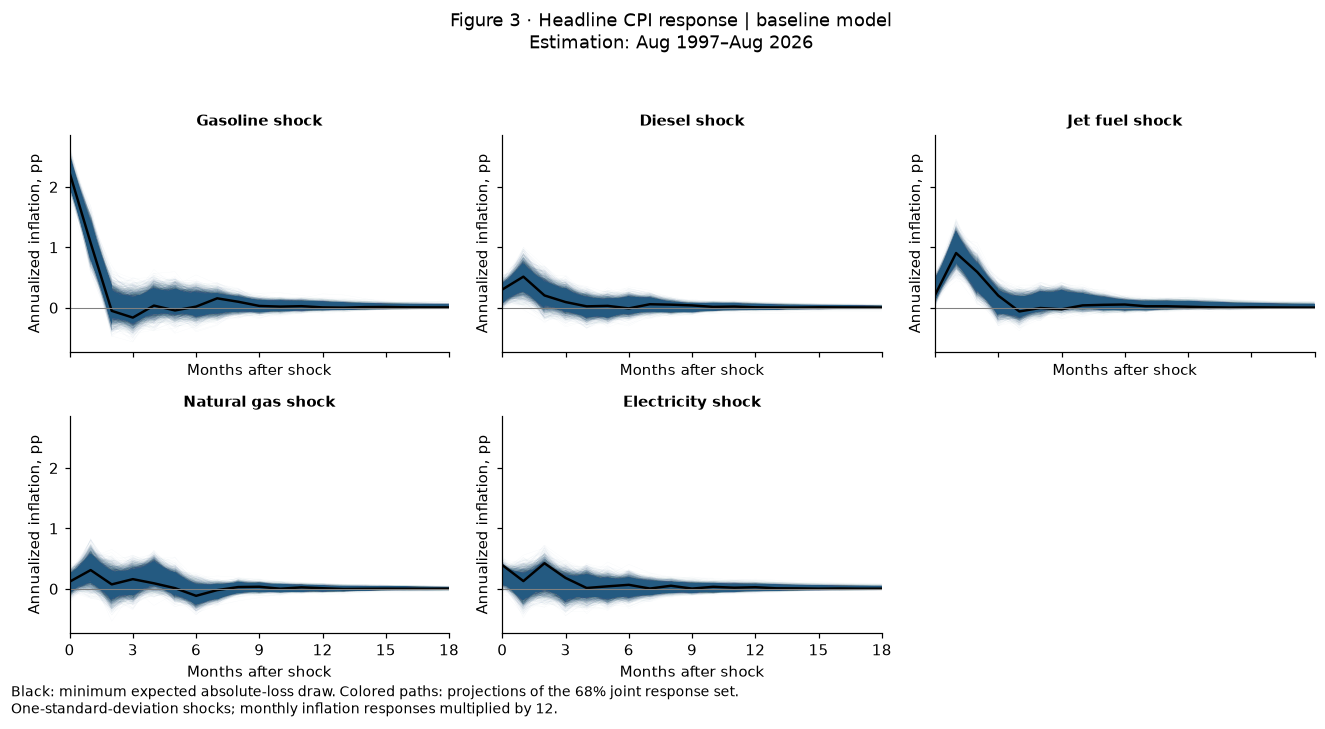

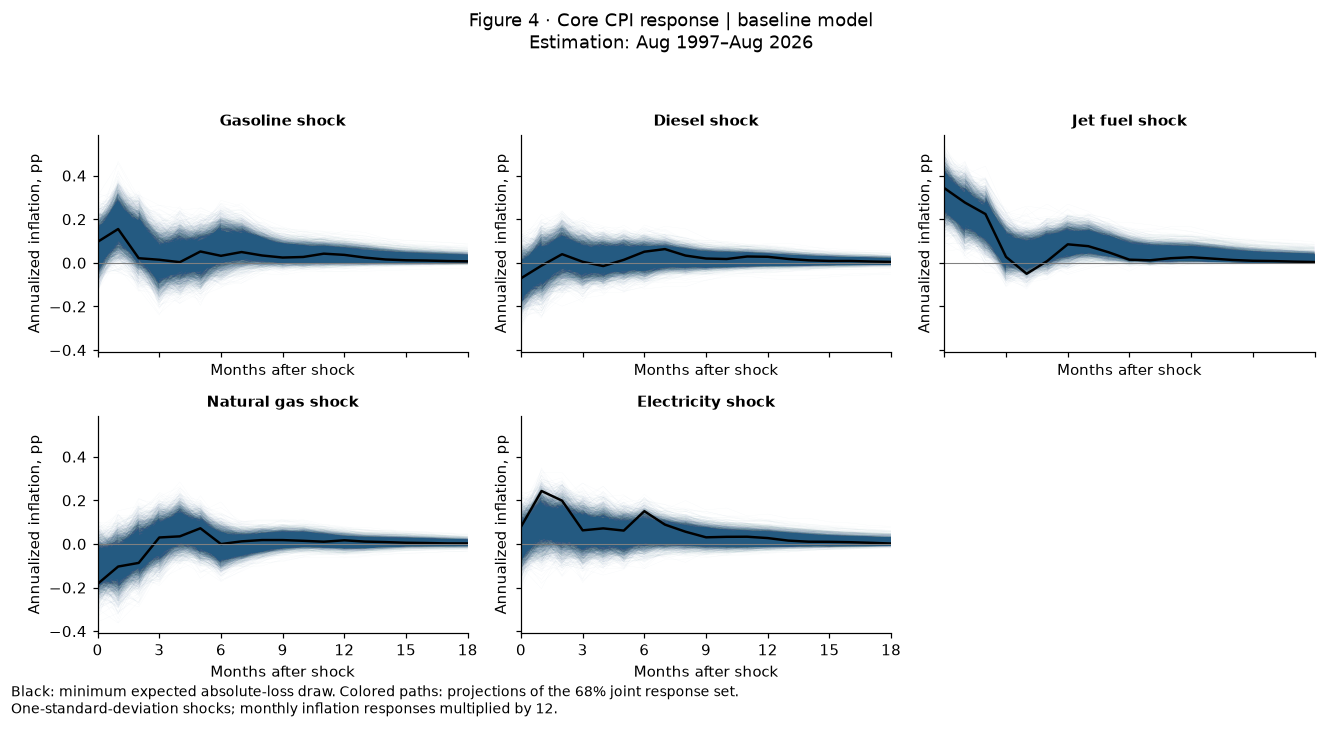

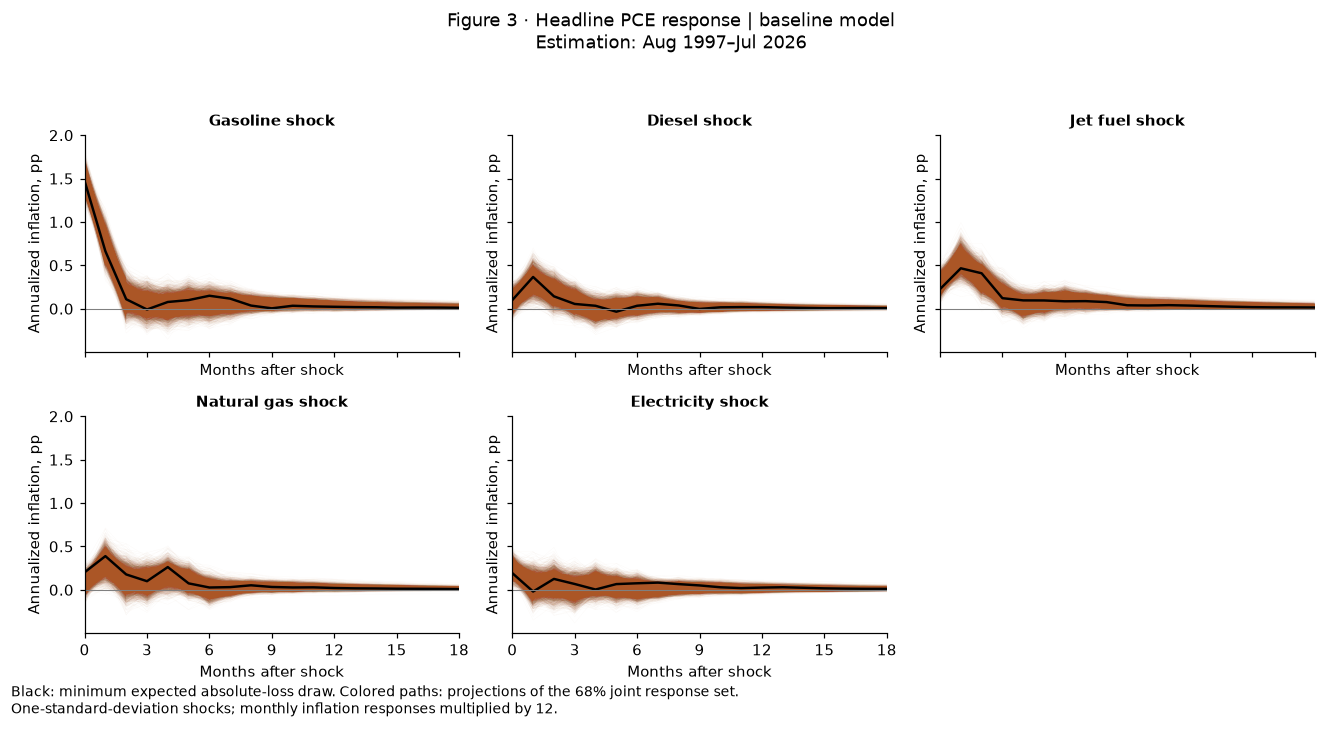

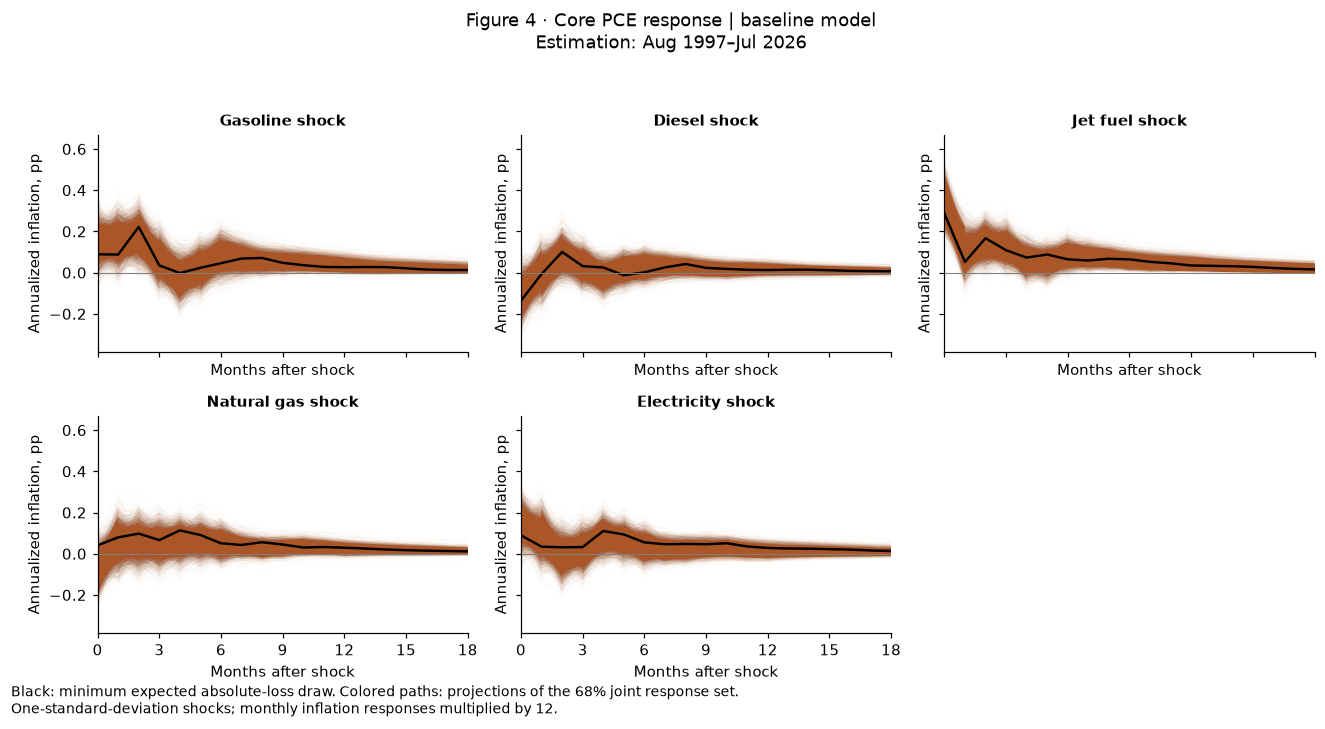

### Table 2 · Long-run variance shares — baseline model
Percent of total inflation variance: median [16th, 84th percentile]. CPI through August 2026; PCE through July 2026.

,Gasoline,Diesel,Jet fuel,Natural gas,Electricity
Headline CPI,"53.4 [49.2, 57.4]","3.6 [2.1, 5.7]","11.8 [9.0, 15.0]","2.5 [1.5, 4.1]","1.6 [0.9, 2.6]"
Core CPI,"4.1 [2.1, 6.9]","1.2 [0.6, 2.2]","10.6 [7.3, 14.4]","2.0 [1.1, 3.3]","2.1 [0.9, 4.3]"
Headline PCE,"45.1 [40.6, 49.5]","3.0 [1.7, 4.9]","9.8 [7.1, 12.8]","3.3 [1.8, 5.4]","1.9 [1.2, 3.1]"
Core PCE,"5.7 [3.5, 8.7]","1.8 [1.0, 2.9]","9.4 [6.6, 12.7]","2.1 [1.1, 3.7]","2.6 [1.4, 4.5]"


In [10]:
for measure in ["CPI", "PCE"]:
    r = results[("Baseline", measure)]
    plot_irf(r, 3, measure, "Baseline", 0)
    plot_irf(r, 4, measure, "Baseline", 1)
variance_table(results, "Baseline", 2)

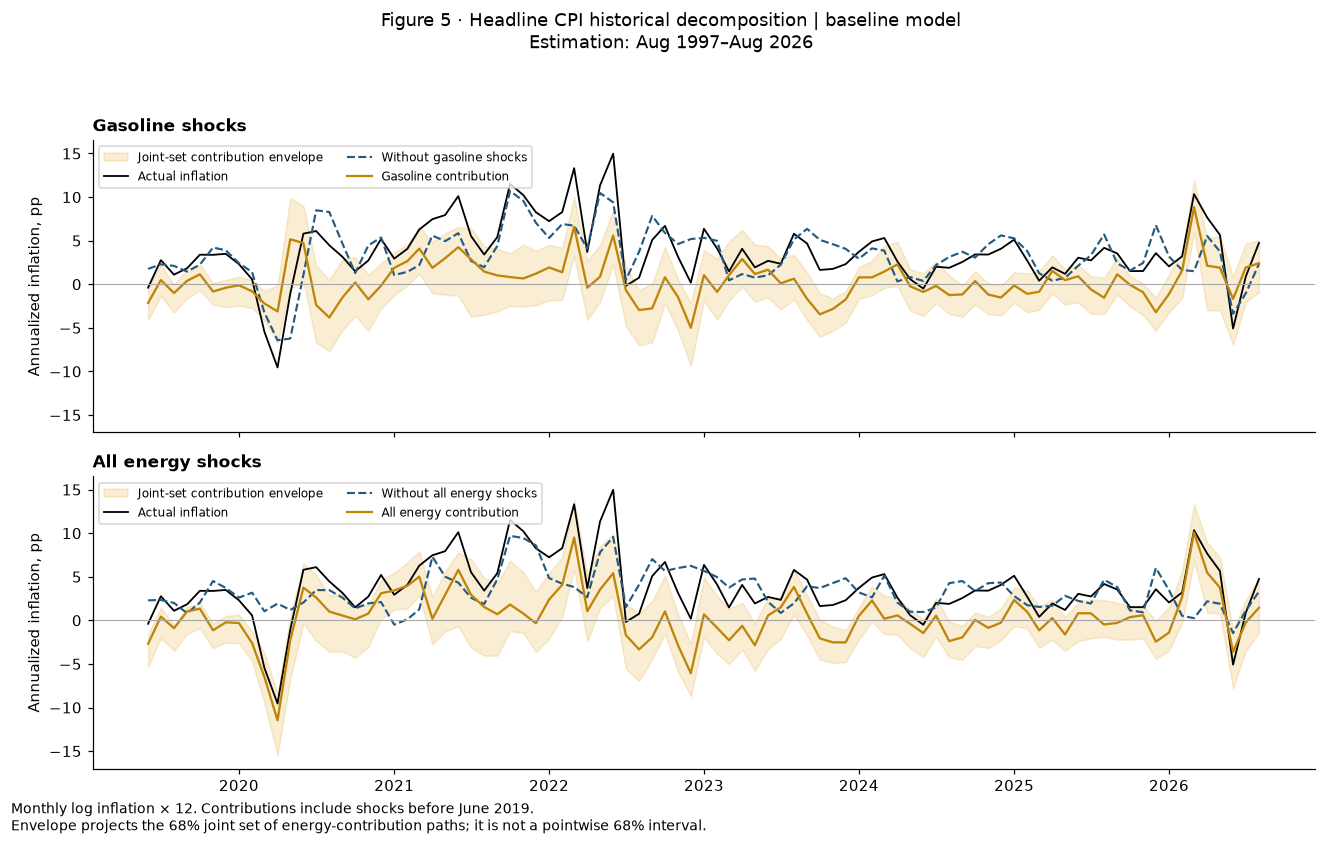

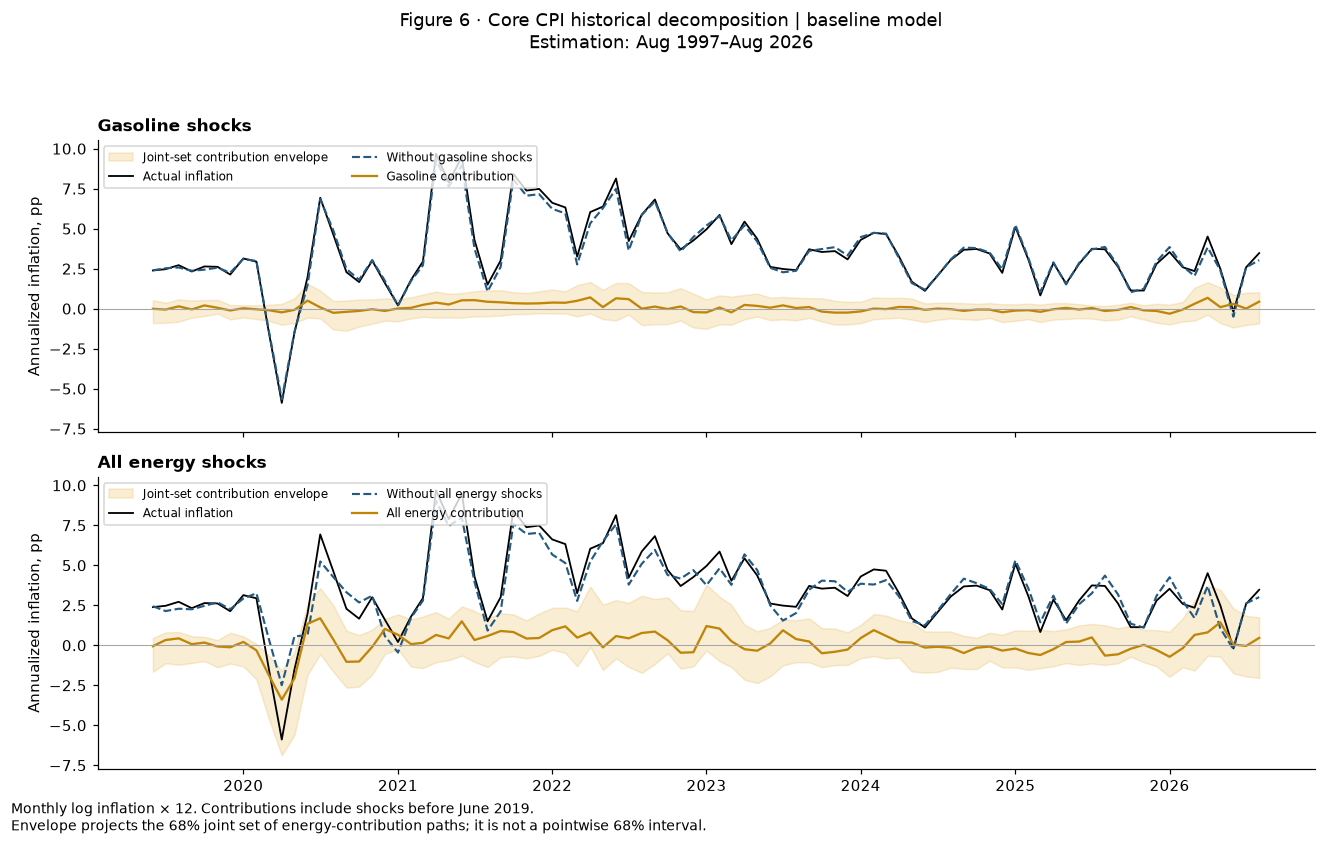

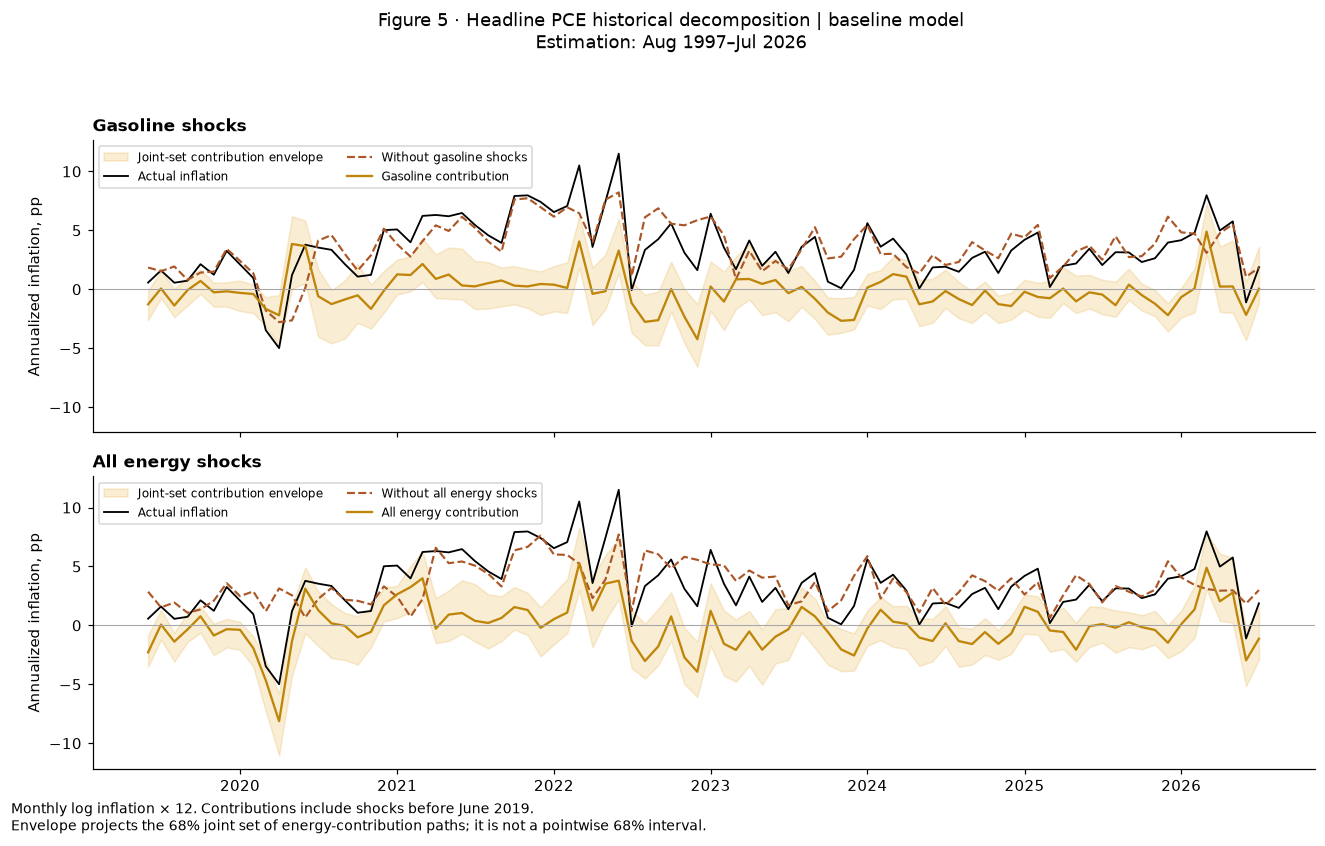

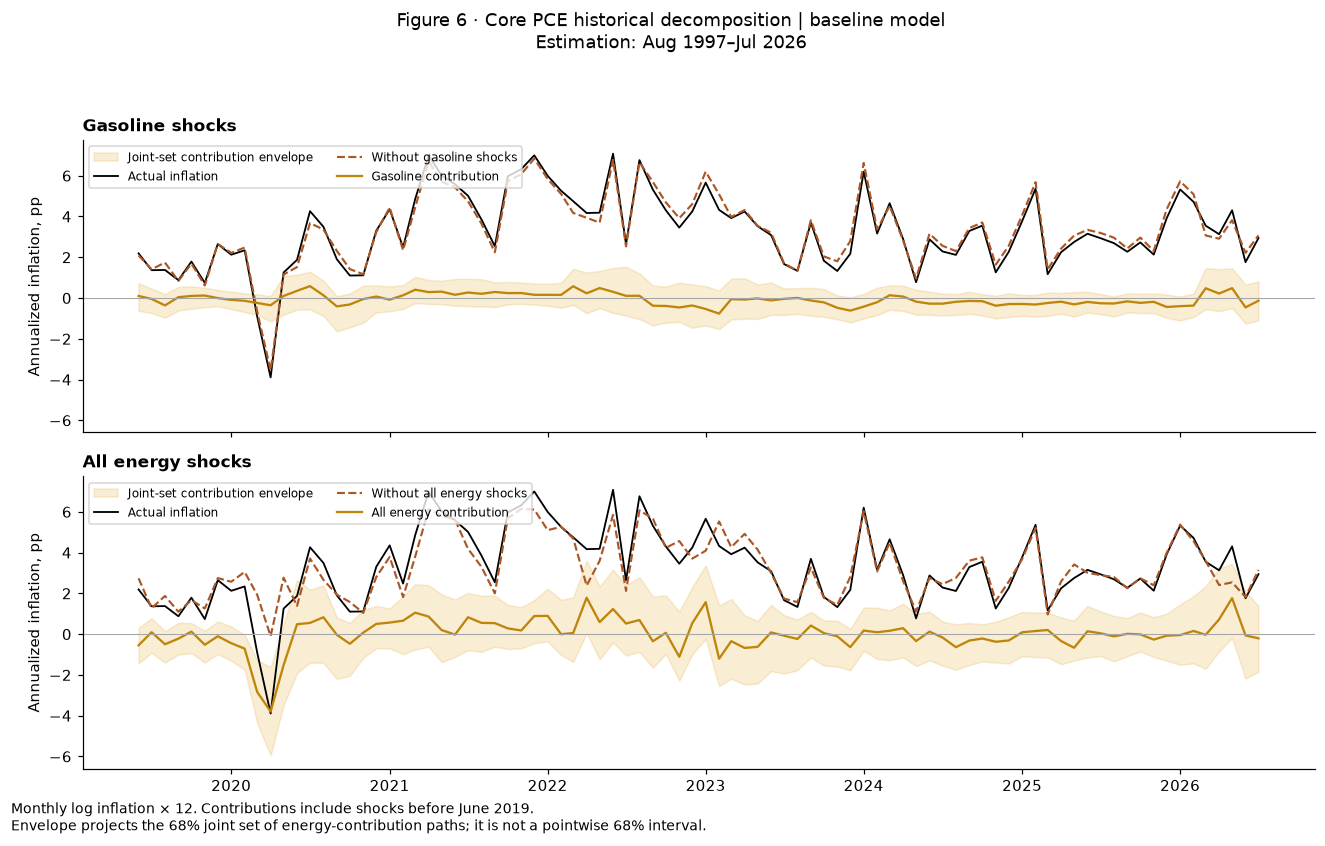

In [11]:
for measure in ["CPI", "PCE"]:
    r = results[("Baseline", measure)]
    plot_history(r, 5, measure, "Baseline", 0)
    plot_history(r, 6, measure, "Baseline", 1)

## 7. Cointegration specification — Figures 7–10 and Table 3
Diesel and jet-fuel log price spreads relative to gasoline replace their growth rates. The other variables, ordering, lag length, and estimation sample within each inflation measure are unchanged. This imposes the paper's unit-coefficient price relationships; it does not estimate a cointegration rank or assume cointegration between natural gas and electricity.

In [12]:
for model_number, measure in enumerate(["CPI", "PCE"], start=2):
    print(f"\nCointegration / {measure}", flush=True)
    results[("Cointegration", measure)] = estimate(models[("Cointegration", measure)], BASE_SEED + model_number, keep_draws=(measure == "PCE"))
display(pd.DataFrame({m: results[("Cointegration", m)]["diagnostics"] for m in ["CPI", "PCE"]}).T)


Cointegration / CPI


2,248/10,000 stable draws; 18.5s


4,241/10,000 stable draws; 30.9s


6,231/10,000 stable draws; 41.9s


8,225/10,000 stable draws; 55.8s


...

4,241/10,000 stable draws; 18.9s


6,238/10,000 stable draws; 27.8s


8,234/10,000 stable draws; 36.3s


10,000/10,000 stable draws; 43.6s


,Draws,Rejected unstable,Acceptance %,Estimation start,Endpoint,Observations,Largest retained root,Reconstruction max error,Seed,Seconds
CPI,10000,37,99.631364,1997-08-01 00:00:00,2026-08-01 00:00:00,349,0.999528,0.0,2226,66.2905
PCE,10000,21,99.79044,1997-08-01 00:00:00,2026-07-01 00:00:00,348,0.999581,0.0,2227,45.980671


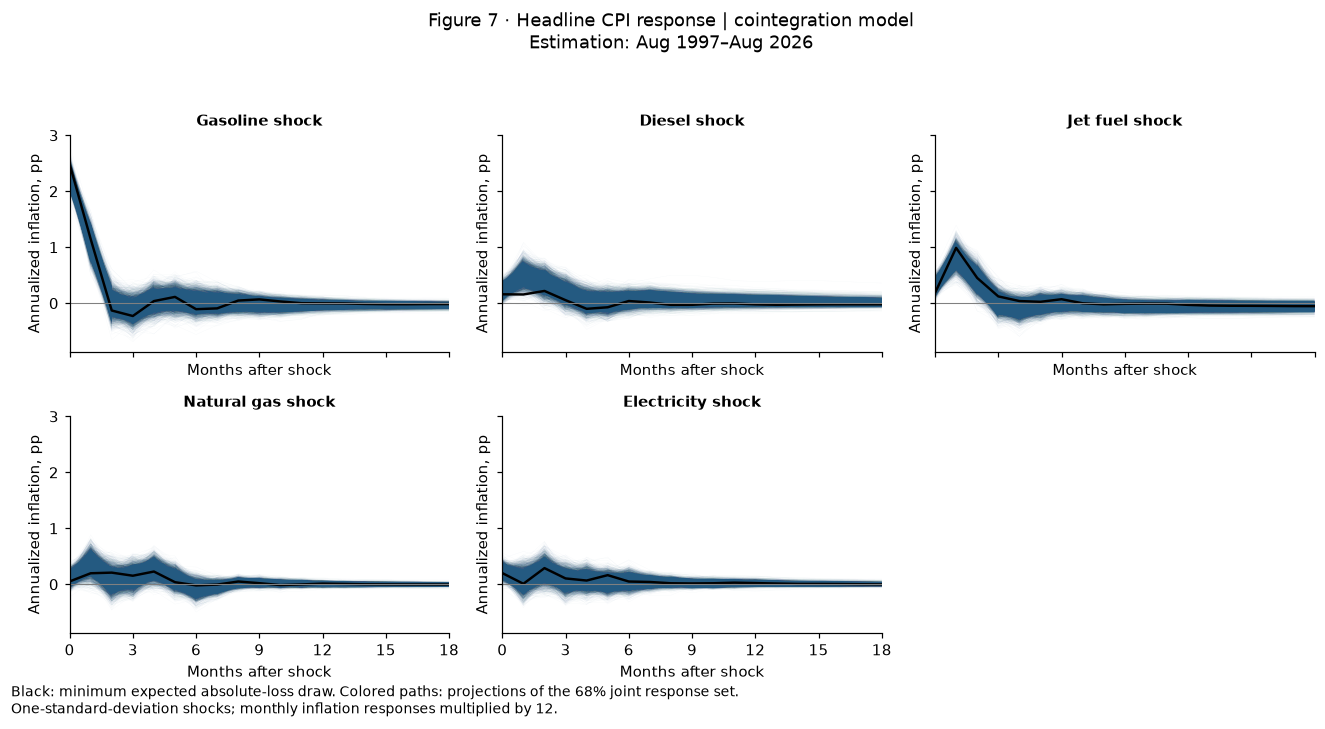

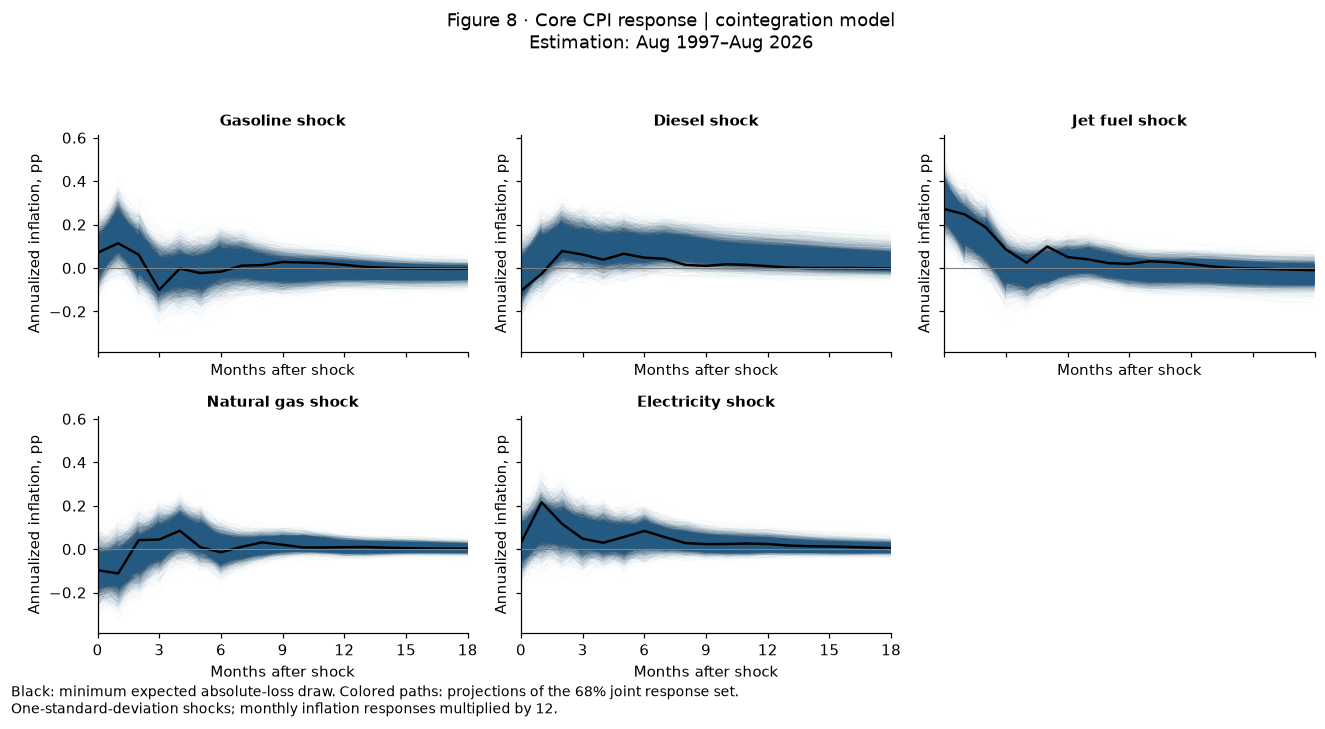

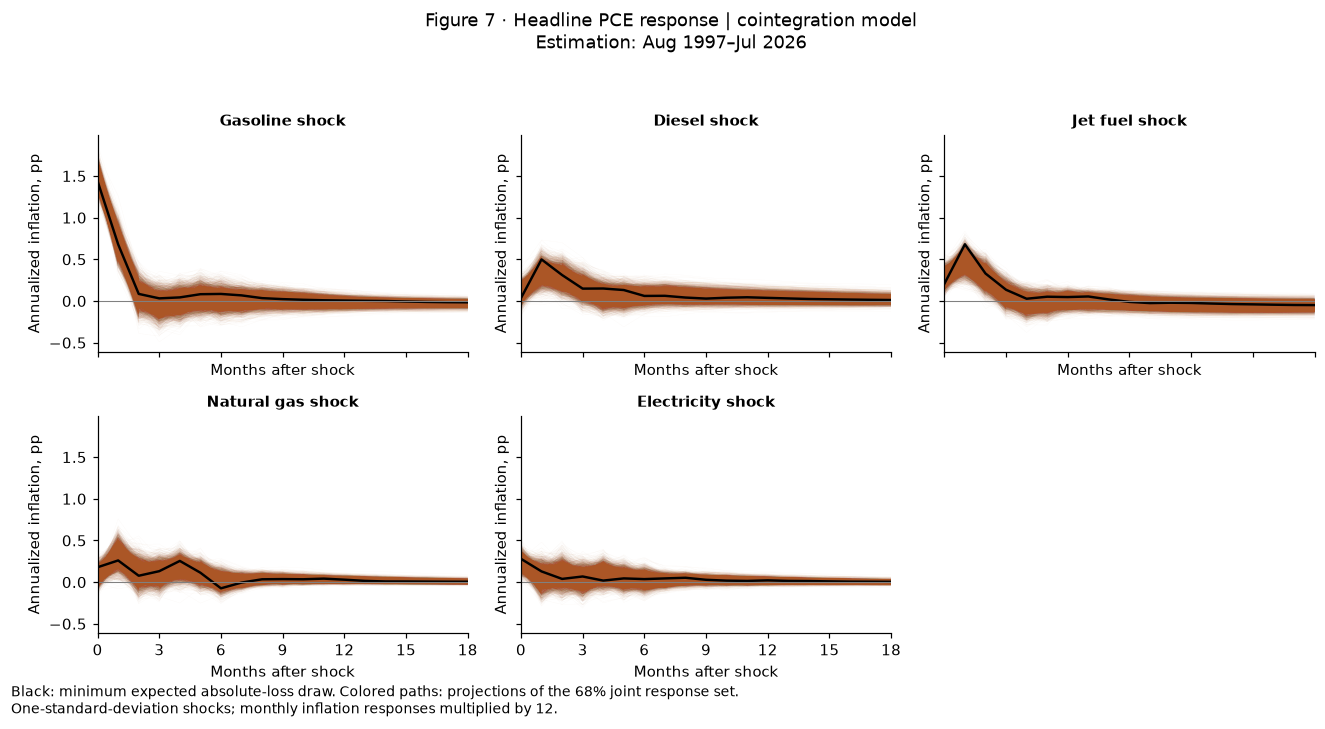

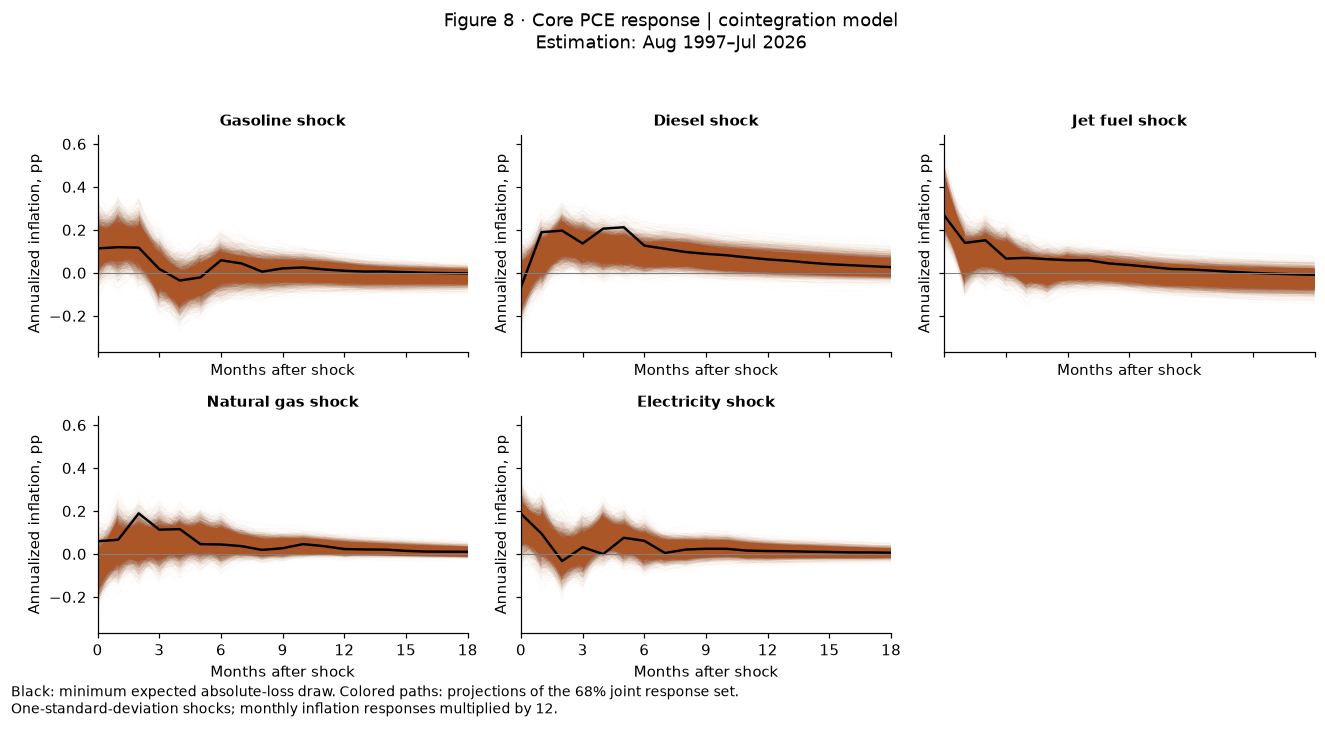

### Table 3 · Long-run variance shares — cointegration model
Percent of total inflation variance: median [16th, 84th percentile]. CPI through August 2026; PCE through July 2026.

,Gasoline,Diesel,Jet fuel,Natural gas,Electricity
Headline CPI,"53.2 [49.0, 57.3]","4.9 [3.0, 7.5]","9.7 [7.2, 12.6]","2.8 [1.7, 4.4]","1.8 [1.0, 3.1]"
Core CPI,"3.3 [1.9, 5.3]","5.3 [2.5, 9.6]","8.2 [5.5, 11.7]","2.1 [1.2, 3.5]","2.5 [1.1, 4.7]"
Headline PCE,"44.0 [39.4, 48.4]","5.1 [2.9, 8.0]","8.4 [5.9, 11.4]","3.5 [2.0, 5.6]","2.0 [1.2, 3.3]"
Core PCE,"4.3 [2.8, 6.5]","6.1 [3.4, 10.1]","7.9 [5.4, 11.2]","2.2 [1.2, 3.8]","2.7 [1.5, 4.5]"


In [13]:
for measure in ["CPI", "PCE"]:
    r = results[("Cointegration", measure)]
    plot_irf(r, 7, measure, "Cointegration", 0)
    plot_irf(r, 8, measure, "Cointegration", 1)
variance_table(results, "Cointegration", 3)

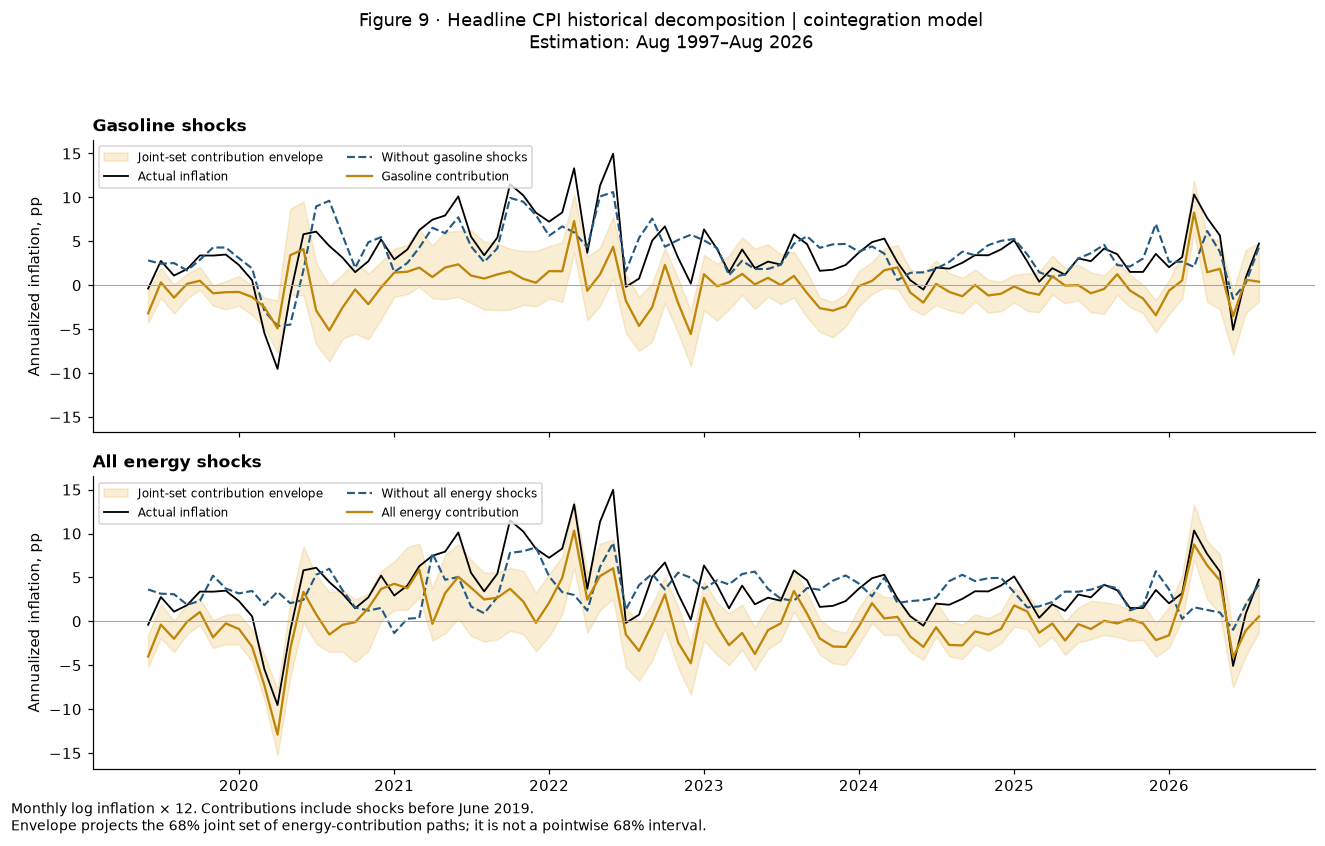

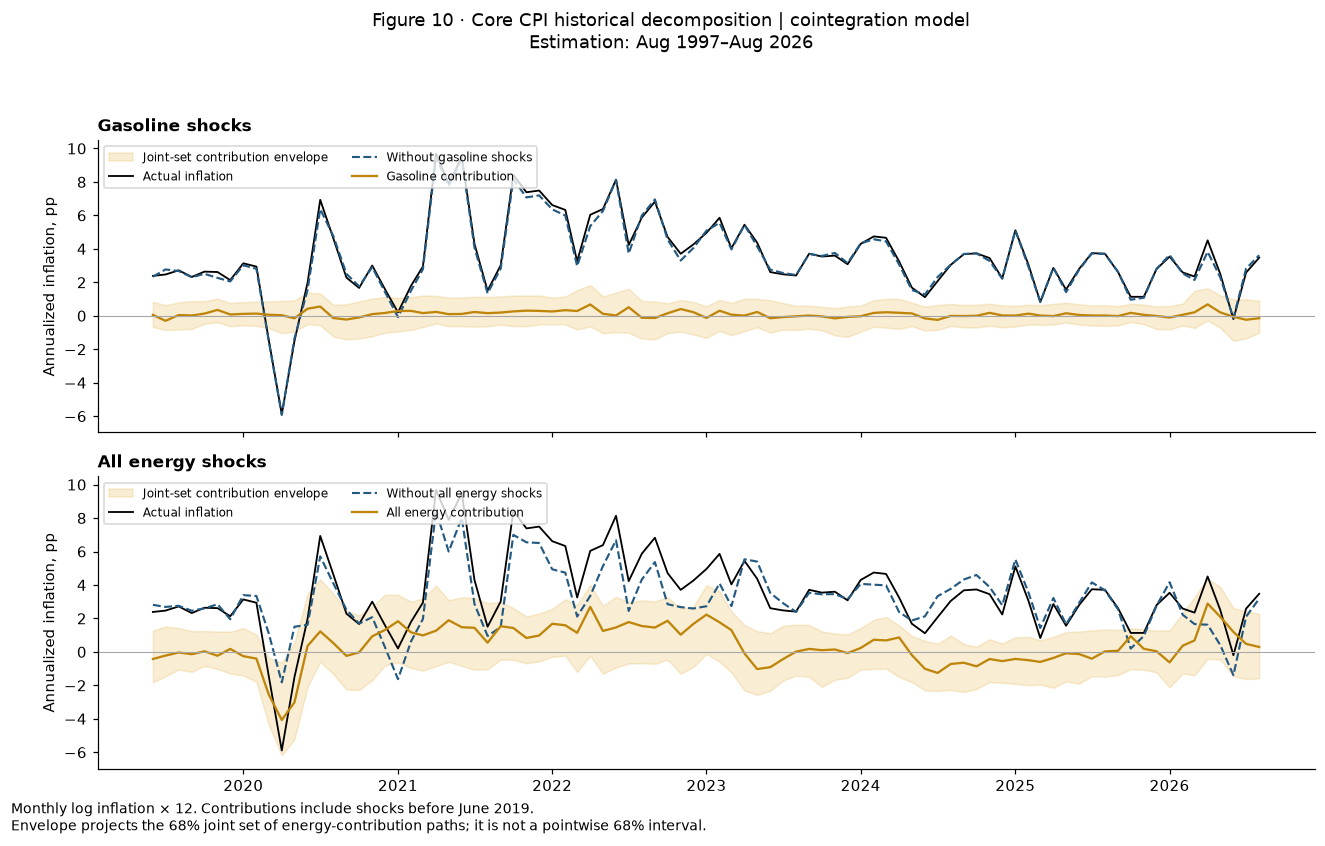

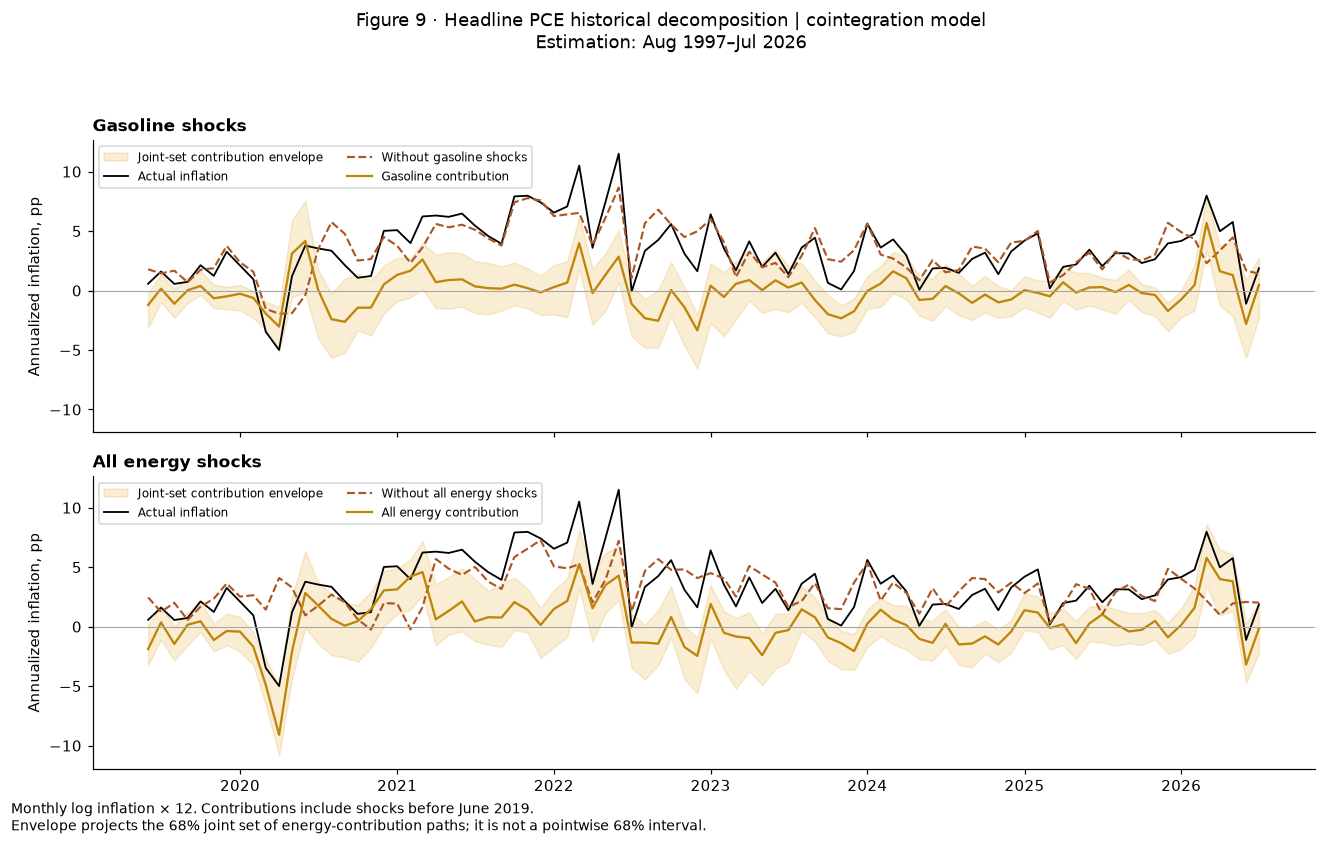

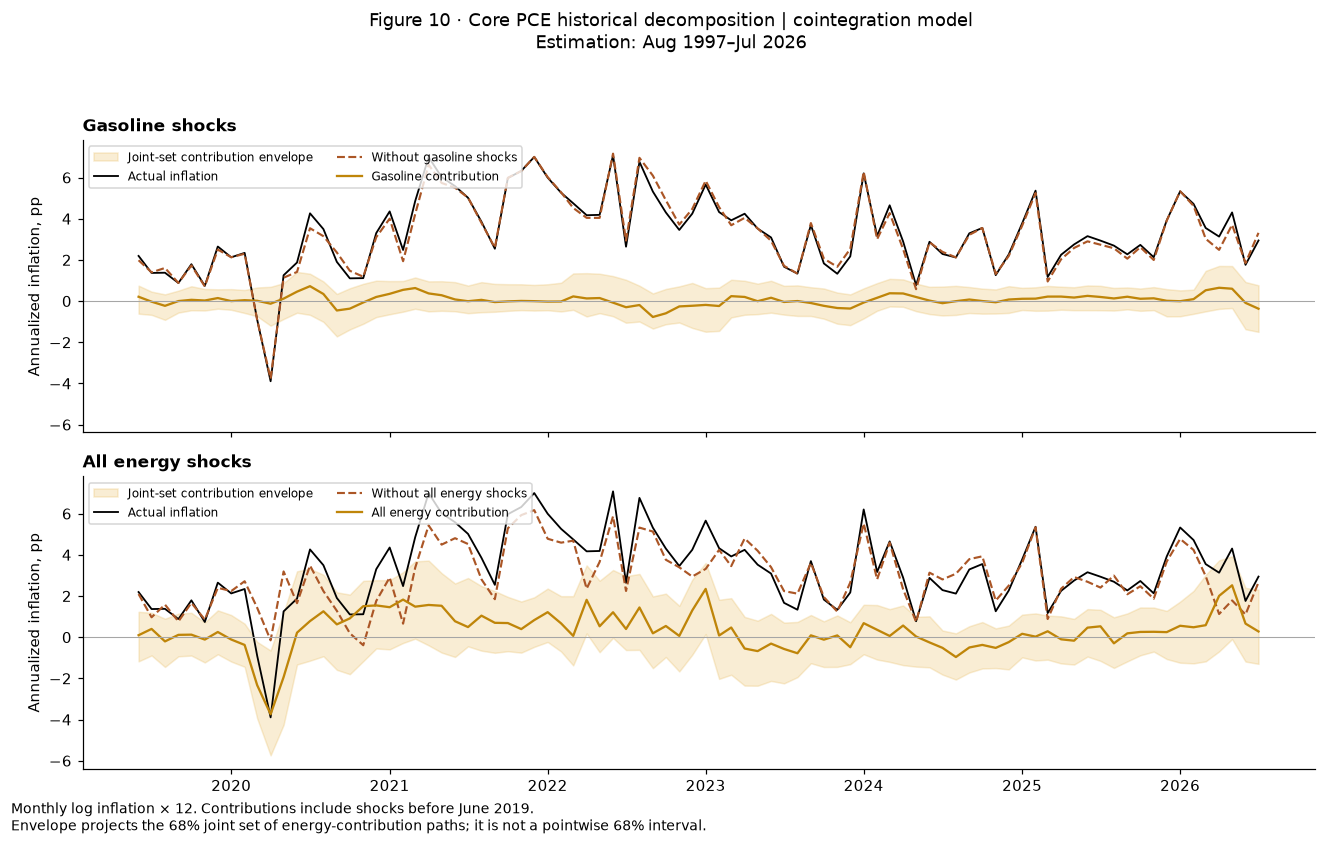

In [14]:
for measure in ["CPI", "PCE"]:
    r = results[("Cointegration", measure)]
    plot_history(r, 9, measure, "Cointegration", 0)
    plot_history(r, 10, measure, "Cointegration", 1)

## 8. CPI–PCE comparison and interpretation

CPI and PCE share the same energy definitions and starting date. **By default they use different latest endpoints.** Their coefficients, residual covariance matrices, one-standard-deviation shocks, and endpoint-specific electricity adjustments can differ. Response differences therefore combine inflation-measure and estimation-sample effects; they are not a fixed-dollar-shock causal comparison. Set `MATCH_ENDPOINTS = True` and rerun for a common-endpoint comparison.

Latest-month tables include dates on every row. Calendar-year averages use annualized monthly log rates, **not year-over-year inflation or annual-average price-index changes**. Incomplete years are labeled YTD and show the number of months. A separate common-calendar-window table compares YTD histories over the same months, but does not refit the models on a common sample. Historical point estimates come from each model's selected joint historical draw, not separately chosen medians.


In [15]:
latest, annual, share_rows, accounting = [], [], [], []
for (specification, measure), r in results.items():
    chosen = r["hd"][r["best_hd"]]
    history_dates = r["dates"]
    for v, kind in enumerate(["Headline", "Core"]):
        actual = 12*r["actual"][:, v]
        gas = 12*chosen[:, v, 0]
        energy = 12*chosen[:, v, :5].sum(axis=-1)
        latest.append({"Month": r["end"].strftime("%Y-%m"), "Model": specification, "Inflation": f"{kind} {measure}",
            "Actual": actual[-1], "Gasoline": gas[-1], "All energy": energy[-1],
            "Without energy shocks": actual[-1]-energy[-1]})
        annual_data = pd.DataFrame({"Actual": actual, "Gasoline": gas, "All energy": energy}, index=history_dates)
        for year, group in annual_data.loc["2020-01-01":].groupby(lambda d: d.year):
            annual.append({"Model": specification, "Inflation": f"{kind} {measure}",
                "Year": f"{year}" + (" YTD" if len(group)<12 else ""), "Months": len(group), **group.mean().to_dict()})
        total_share = r["fevd"][:, v, :5].sum(axis=-1)
        q = np.quantile(total_share, [0.16, 0.5, 0.84])
        share_rows.append({"Through": r["end"].strftime("%Y-%m"), "Model": specification, "Inflation": f"{kind} {measure}",
                          "All-energy variance share": f"{q[1]:.1f} [{q[0]:.1f}, {q[2]:.1f}]"})
        accounting.append({"Month": r["end"].strftime("%Y-%m"), "Model": specification, "Inflation": f"{kind} {measure}",
            "Energy shocks": energy[-1], "Other two shocks": 12*chosen[-1, v, 5:7].sum(),
            "Intercept": 12*chosen[-1, v, 7], "Initial conditions": 12*chosen[-1, v, 8], "Actual": actual[-1]})

display(Markdown("### Latest available month for each model\nAnnualized monthly log rates / percentage-point contributions; dates can differ."))
display(pd.DataFrame(latest).round(3))
display(Markdown("### Calendar-year means (annualized monthly log rates)"))
annual_summary = pd.DataFrame(annual)
for specification in ["Baseline", "Cointegration"]:
    display(Markdown(f"**{specification}**"))
    display(annual_summary[annual_summary.Model.eq(specification)].drop(columns="Model").set_index(["Inflation", "Year"]).round(3))
display(Markdown("### Combined energy share of long-run inflation variance\nMedian [16th, 84th percentile], calculated after summing within each draw."))
display(pd.DataFrame(share_rows))
display(Markdown("### Latest-month accounting check\nEnergy + other shocks + intercept + initial conditions = actual inflation."))
display(pd.DataFrame(accounting).round(4))

display(Markdown("### Reading the updated estimates"))
for specification in ["Baseline", "Cointegration"]:
    cpi = results[(specification, "CPI")]
    pce = results[(specification, "PCE")]
    cpi_share = np.median(cpi["fevd"][..., :5].sum(axis=-1), axis=0)
    pce_share = np.median(pce["fevd"][..., :5].sum(axis=-1), axis=0)
    display(Markdown(f"**{specification}.** The five energy shocks account for a posterior median "
        f"**{cpi_share[0]:.1f}%** of headline CPI's long-run variance and **{pce_share[0]:.1f}%** "
        f"of headline PCE's. The corresponding core shares are **{cpi_share[1]:.1f}%** and "
        f"**{pce_share[1]:.1f}%**. These variance shares describe average fluctuations, "
        "not the fraction of the inflation level attributable to energy in a particular month."))
    for measure in ["CPI", "PCE"]:
        row = next(x for x in latest if x["Model"] == specification and x["Inflation"] == f"Headline {measure}")
        display(Markdown(f"In {row['Month']}, headline {measure} inflation was **{row['Actual']:.2f}%** "
            f"at an annualized monthly log rate. The selected historical draw attributes "
            f"**{row['All energy']:+.2f} percentage points** to energy shocks, implying "
            f"a counterfactual rate of **{row['Without energy shocks']:.2f}%**. "
            "The historical figures show joint uncertainty around the contribution."))

# Equal calendar months for the YTD comparison, using the already fitted models.
common_end = min(endpoints.values())
common_rows = []
for (specification, measure), r in results.items():
    mask = (r["dates"].year == common_end.year) & (r["dates"] <= common_end)
    for v, kind in enumerate(["Headline", "Core"]):
        chosen = r["hd"][r["best_hd"]]
        common_rows.append({"Model": specification, "Inflation": f"{kind} {measure}",
            "Common window": f"{common_end.year}-01 to {common_end:%Y-%m}", "Months": int(mask.sum()),
            "Actual": (12*r["actual"][mask, v]).mean(),
            "All energy": (12*chosen[mask, v, :5].sum(axis=-1)).mean()})
display(Markdown("### Same-month YTD history comparison\nSame calendar window; fitted model endpoints may still differ."))
display(pd.DataFrame(common_rows).round(3))


### Latest available month for each model
Annualized monthly log rates / percentage-point contributions; dates can differ.

,Month,Model,Inflation,Actual,Gasoline,All energy,Without energy shocks
0,2026-08,Baseline,Headline CPI,4.743,2.412,1.443,3.300
1,2026-08,Baseline,Core CPI,3.473,0.439,0.462,3.010
2,2026-07,Baseline,Headline PCE,1.870,0.046,-1.127,2.997
3,2026-07,Baseline,Core PCE,2.943,-0.131,-0.206,3.149
4,2026-08,Cointegration,Headline CPI,4.743,0.399,0.548,4.194
5,2026-08,Cointegration,Core CPI,3.473,-0.146,0.295,3.178
6,2026-07,Cointegration,Headline PCE,1.870,0.474,-0.148,2.018
7,2026-07,Cointegration,Core PCE,2.943,-0.371,0.278,2.665


### Calendar-year means (annualized monthly log rates)

**Baseline**

Months  Actual  Gasoline  All energy
Inflation    Year                                          
Headline CPI 2020          12   1.312    -0.481      -0.933
             2021          12   6.929     2.147       2.393
             2022          12   6.208     0.321       0.920
             2023          12   3.262    -0.171      -0.533
             2024          12   2.830    -0.062      -0.266
             2025          12   2.619    -0.366       0.013
             2026 YTD       8   3.681     1.995       2.274
Core CPI     2020          12   1.611    -0.051      -0.429
             2021          12   5.344     0.318       0.581
             2022          12   5.530     0.275       0.445
             2023          12   3.841    -0.022       0.203
             2024          12   3.163    -0.048       0.076
             2025          12   2.612    -0.066      -0.192
             2026 YTD       8   2.666     0.180       0.308
Headline PCE 2020          12   1.326    -0.175      -0.981
             2021          12   5.961     0.799       1.287
             2022          12   5.373    -0.484       0.292
             2023          12   2.730    -0.505      -0.759
             2024          12   2.692    -0.358      -0.536
             2025          12   2.837    -0.681      -0.187
             2026 YTD       7   4.062     0.377       1.012
Core PCE     2020          12   1.498    -0.029      -0.614
             2021          12   5.083     0.220       0.550
             2022          12   4.847     0.045       0.410
             2023          12   3.065    -0.253      -0.148
             2024          12   2.945    -0.192      -0.126
             2025          12   2.928    -0.257      -0.068
             2026 YTD       7   3.676    -0.025       0.328

...

**Cointegration.** The five energy shocks account for a posterior median **73.6%** of headline CPI's long-run variance and **64.3%** of headline PCE's. The corresponding core shares are **23.1%** and **24.9%**. These variance shares describe average fluctuations, not the fraction of the inflation level attributable to energy in a particular month.

In 2026-08, headline CPI inflation was **4.74%** at an annualized monthly log rate. The selected historical draw attributes **+0.55 percentage points** to energy shocks, implying a counterfactual rate of **4.19%**. The historical figures show joint uncertainty around the contribution.

In 2026-07, headline PCE inflation was **1.87%** at an annualized monthly log rate. The selected historical draw attributes **-0.15 percentage points** to energy shocks, implying a counterfactual rate of **2.02%**. The historical figures show joint uncertainty around the contribution.

### Same-month YTD history comparison
Same calendar window; fitted model endpoints may still differ.

,Model,Inflation,Common window,Months,Actual,All energy
0,Baseline,Headline CPI,2026-01 to 2026-07,7,3.529,2.393
1,Baseline,Core CPI,2026-01 to 2026-07,7,2.551,0.286
2,Baseline,Headline PCE,2026-01 to 2026-07,7,4.062,1.012
3,Baseline,Core PCE,2026-01 to 2026-07,7,3.676,0.328
4,Cointegration,Headline CPI,2026-01 to 2026-07,7,3.529,2.274
5,Cointegration,Core CPI,2026-01 to 2026-07,7,2.551,1.011
6,Cointegration,Headline PCE,2026-01 to 2026-07,7,4.062,1.712
7,Cointegration,Core PCE,2026-01 to 2026-07,7,3.676,1.012


## 9. Energy shocks and year-over-year core PCE inflation

**Question:** How much did the five energy shocks occurring during March–July 2026 contribute to July 2026 core PCE inflation, measured year over year?

This calculation uses the actual downloaded `PCEPILFE` index values for July 2026 and July 2025. It does **not** substitute a rounded 3.3% rate. The dates below are fixed to the requested episode; change them to examine another episode. The model itself is still estimated through its available endpoint, so estimates may change with new observations and revisions.

For each accepted PCE posterior draw, recover the structural innovations using its own coefficients and Cholesky factor. Retain only the first five shocks dated within the selected window, set all other shocks and initial contributions to zero, and propagate the retained shocks through the VAR. This yields their contribution $c_t$ to monthly core PCE log inflation, in units of $100\Delta\log P_t$. All effects of shocks occurring before the selected window remain in the counterfactual.

Accumulate the monthly contributions into a price-level effect $C_t=\sum_{s\leq t}c_s$, with $C_t=0$ before the first retained shock. Then calculate

$$\pi_t^{yy}=100\left(\frac{P_t}{P_{t-12}}-1\right),\qquad
\pi_{t,\mathrm{without}}^{yy}=100\left[\frac{P_t}{P_{t-12}}
\exp\left(-\frac{C_t-C_{t-12}}{100}\right)-1\right].$$

The contribution in **percentage points of conventional y/y inflation** is $\pi_t^{yy}-\pi_{t,\mathrm{without}}^{yy}$. For July 2026 and shocks beginning in March 2026, $C_{t-12}=0$: July 2025's denominator is unchanged. The general formula also adjusts the denominator if the chosen episode starts before the comparison year.

The monthly audit shows both $c_t$ and its annualized display value $12c_t$. Sum the **unannualized** contributions to obtain $C_t$; do not insert an average annualized monthly rate into the y/y formula.

Point estimates use each model's existing minimum-risk historical draw, preserving consistency with its historical figures. Posterior medians and equal-tailed 68% intervals are calculated separately for this new scalar contribution across all 10,000 draws. The selected historical draw need not lie inside that scalar interval. Baseline is the main estimate; cointegration is the sensitivity specification.


In [16]:
def energy_window_effects(frame, result, shock_start, shock_end, through):
    """Monthly log-rate effects of energy shocks dated only within the chosen window."""
    b, impact = result["coefficients"], result["impacts"]
    if b is None or impact is None:
        raise ValueError("Estimate this model with keep_draws=True first.")
    n = frame.shape[1]
    p = (b.shape[1] - 1) // n
    dates = frame.index[p:]
    shock_start, shock_end, through = map(pd.Timestamp, [shock_start, shock_end, through])
    if not (dates[0] <= shock_start <= shock_end <= through <= dates[-1]):
        raise ValueError("The shock window and evaluation month must lie within the fitted sample.")
    if not all(d in dates for d in [shock_start, shock_end, through]):
        raise ValueError("Use monthly dates on the first day of each month.")
    x, target = lagged_design(frame.to_numpy(), p)
    residuals = target[None] - x[None] @ b
    shocks = np.linalg.solve(impact, residuals.swapaxes(1, 2)).swapaxes(1, 2)
    a = unpack_coefficients(b, p, n)
    positions = np.flatnonzero((dates >= shock_start) & (dates <= through))
    buffer = np.zeros((p, len(b), n))
    effects = np.empty((len(b), len(positions), n))
    for j, t in enumerate(positions):
        current = np.zeros((len(b), n))
        for lag in range(p):
            current += np.einsum("dij,dj->di", a[:, lag], buffer[lag])
        if dates[t] <= shock_end:
            current += np.einsum("dij,dj->di", impact[:, :, :5], shocks[:, t, :5])
        effects[:, j] = current
        buffer[1:] = buffer[:-1].copy()
        buffer[0] = current
    return dates[positions], effects


def yoy_counterfactual(current_index, prior_year_index, cumulative_log_effect):
    """Effect is the difference C[t] - C[t-12], in log percentage points."""
    if current_index <= 0 or prior_year_index <= 0:
        raise ValueError("Both price-index observations must be positive.")
    gross = current_index / prior_year_index
    actual = 100 * (gross - 1)
    contribution = -100 * gross * np.expm1(-np.asarray(cumulative_log_effect) / 100)
    without = 100 * (gross * np.exp(-np.asarray(cumulative_log_effect) / 100) - 1)
    np.testing.assert_allclose(without + contribution, actual, atol=1e-10)
    return actual, without, contribution


In [17]:
# Verify the retained-shock recursion against an independent IRF convolution.
rng = np.random.default_rng(202603)
n, p, t_count = 7, 2, 42
a = np.stack([0.30*np.eye(n), 0.10*np.eye(n)])
impact = np.eye(n)
impact[-1, 0] = 0.4
impact[-1, 2] = 0.2
b = np.vstack([np.full((1, n), 0.02), a[0].T, a[1].T])
innovations = rng.normal(size=(t_count, n))
y = np.zeros((t_count, n))
for t in range(p, t_count):
    y[t] = b[0] + a[0]@y[t-1] + a[1]@y[t-2] + impact@innovations[t]
toy = pd.DataFrame(y, index=pd.date_range("2020-01-01", periods=t_count, freq="MS"))
toy_result = {"coefficients": b[None], "impacts": impact[None]}
start, stop, end = toy.index[10], toy.index[13], toy.index[30]
test_dates, measured = energy_window_effects(toy, toy_result, start, stop, end)
responses = impulse_responses(a[None], impact[None], 30)[0]
expected = np.zeros_like(measured[0])
for j, date in enumerate(test_dates):
    t = toy.index.get_loc(date)
    for shock_t in range(10, min(t, 13)+1):
        expected[j] += responses[t-shock_t, :, :5]@innovations[shock_t, :5]
np.testing.assert_allclose(measured[0], expected, atol=1e-11)

# Verify exact conventional y/y conversion, including an affected denominator.
levels_test = np.cumsum(measured[0, :, -1])
delta = levels_test[-1] - levels_test[-13]
actual_test, without_test, contribution_test = yoy_counterfactual(130.123, 125.456, delta)
direct_without = 100*((130.123*np.exp(-levels_test[-1]/100)) /
                     (125.456*np.exp(-levels_test[-13]/100)) - 1)
np.testing.assert_allclose(without_test, direct_without, atol=1e-11)
np.testing.assert_allclose(yoy_counterfactual(130.123, 125.456, 0)[2], 0, atol=0)
display(Markdown("**Passed:** dated-shock recursion versus IRF convolution, exact y/y subtraction, "
    "zero-shock identity, and counterfactual adjustment of both price-index dates."))


**Passed:** dated-shock recursion versus IRF convolution, exact y/y subtraction, zero-shock identity, and counterfactual adjustment of both price-index dates.

In [18]:
SHOCK_START = pd.Timestamp("2026-03-01")
SHOCK_END = pd.Timestamp("2026-07-01")
YOY_MONTH = pd.Timestamp("2026-07-01")
prior_year = YOY_MONTH - pd.DateOffset(years=1)
core_index = levels["Core PCE"]
if YOY_MONTH > endpoints["PCE"] or prior_year not in core_index.index:
    raise ValueError("The requested y/y comparison is not available in the fitted PCE data.")
index_now, index_before = float(core_index.loc[YOY_MONTH]), float(core_index.loc[prior_year])
assert np.isfinite([index_now, index_before]).all()
actual_yoy = 100 * (index_now/index_before - 1)
display(Markdown(f"### Exact FRED inputs: core PCE ({YOY_MONTH:%B %Y})"))
display(pd.DataFrame({"FRED series": ["PCEPILFE", "PCEPILFE"],
    "Month": [prior_year.strftime("%Y-%m"), YOY_MONTH.strftime("%Y-%m")],
    "Downloaded index": [index_before, index_now]}).style.format({"Downloaded index": "{:.6f}"}))
display(Markdown(f"**Actual conventional y/y inflation:** `100 × ({index_now!r} / {index_before!r} − 1)` "
    f"= **{actual_yoy:.6f}%**. All calculations retain full precision; only displays are rounded."))

yoy_rows, window_monthly_audits = [], {}
for specification in ["Baseline", "Cointegration"]:
    result = results[(specification, "PCE")]
    frame = models[(specification, "PCE")]
    event_dates, event_effects = energy_window_effects(frame, result, SHOCK_START, SHOCK_END, YOY_MONTH)
    monthly_core = event_effects[:, :, -1]  # 100 × monthly log inflation, before annualization
    cumulative = monthly_core.cumsum(axis=1)
    previous_effect = (cumulative[:, event_dates.get_loc(prior_year)]
                       if prior_year in event_dates else np.zeros(DRAWS))
    log_effect = cumulative[:, -1] - previous_effect
    actual, without, contribution = yoy_counterfactual(index_now, index_before, log_effect)
    point = result["best_hd"]
    q16, median, q84 = np.quantile(contribution, [0.16, 0.50, 0.84])
    audit = pd.DataFrame({"Annualized monthly contribution (pp)": 12*monthly_core[point],
        "Monthly log contribution (pp)": monthly_core[point],
        "Cumulative log price effect (pp)": cumulative[point]}, index=event_dates)
    audit.index.name = "Month"
    window_monthly_audits[specification] = audit
    display(Markdown(f"### {specification}: monthly effects of shocks dated "
        f"{SHOCK_START:%B %Y}–{SHOCK_END:%B %Y}"))
    display(audit.style.format("{:.6f}"))
    yoy_rows.append({"Model": specification, "Actual y/y (%)": actual,
        "Without selected-window energy shocks (%)": without[point],
        "Selected-draw contribution (pp)": contribution[point],
        "Posterior median (pp)": median, "68% lower (pp)": q16, "68% upper (pp)": q84})
    display(Markdown(f"Selected historical draw: **{point}**. The relevant cumulative log effect is "
        f"**{log_effect[point]:.6f} pp**. Applying the exact ratio formula gives "
        f"**{contribution[point]:.6f} pp** of {YOY_MONTH:%B %Y} y/y inflation, "
        f"leaving **{without[point]:.6f}% y/y** without the selected-window energy shocks."))
    # Check both the cumulative-rate identity and the counterfactual price-ratio identity.
    np.testing.assert_allclose(audit["Annualized monthly contribution (pp)"].sum()/12,
                               cumulative[point, -1], atol=1e-12)
    np.testing.assert_allclose(without + contribution, actual, atol=1e-10)

yoy_summary = pd.DataFrame(yoy_rows).set_index("Model")
display(Markdown("### Contribution to conventional year-over-year core PCE inflation\n"
    "Percentage points of the actual y/y rate; 68% intervals are scalar posterior percentiles."))
display(yoy_summary.T.style.format("{:.6f}"))
display(Markdown("The contribution isolates shocks dated within the specified window and includes their "
    "propagated effects through the evaluation month. Earlier energy shocks, other shocks, the intercept, "
    "and initial conditions remain in the counterfactual. These are model-based attributions, not a "
    "direct accounting allocation of observed energy-price increases."))


### Exact FRED inputs: core PCE (July 2026)

,FRED series,Month,Downloaded index
0,PCEPILFE,2025-07,126.430000
1,PCEPILFE,2026-07,130.658000


**Actual conventional y/y inflation:** `100 × (130.658 / 126.43 − 1)` = **3.344143%**. All calculations retain full precision; only displays are rounded.

### Baseline: monthly effects of shocks dated March 2026–July 2026

,Annualized monthly contribution (pp),Monthly log contribution (pp),Cumulative log price effect (pp)
Month,,,
2026-03-01 00:00:00,-0.118317,-0.009860,-0.009860
2026-04-01 00:00:00,0.470483,0.039207,0.029347
2026-05-01 00:00:00,1.856791,0.154733,0.184080
2026-06-01 00:00:00,0.010408,0.000867,0.184947
2026-07-01 00:00:00,-0.242499,-0.020208,0.164739


...

,Annualized monthly contribution (pp),Monthly log contribution (pp),Cumulative log price effect (pp)
Month,,,
2026-03-01 00:00:00,0.068930,0.005744,0.005744
2026-04-01 00:00:00,0.732184,0.061015,0.066759
2026-05-01 00:00:00,1.333436,0.111120,0.177879
2026-06-01 00:00:00,0.295497,0.024625,0.202504
2026-07-01 00:00:00,-0.471668,-0.039306,0.163198


Selected historical draw: **6871**. The relevant cumulative log effect is **0.163198 pp**. Applying the exact ratio formula gives **0.168518 pp** of July 2026 y/y inflation, leaving **3.175625% y/y** without the selected-window energy shocks.

### Contribution to conventional year-over-year core PCE inflation
Percentage points of the actual y/y rate; 68% intervals are scalar posterior percentiles.

Model,Baseline,Cointegration
Actual y/y (%),3.344143,3.344143
Without selected-window energy shocks (%),3.174035,3.175625
Selected-draw contribution (pp),0.170108,0.168518
Posterior median (pp),0.181014,0.300553
68% lower (pp),0.079329,0.192965
68% upper (pp),0.285721,0.408498


The contribution isolates shocks dated within the specified window and includes their propagated effects through the evaluation month. Earlier energy shocks, other shocks, the intercept, and initial conditions remain in the counterfactual. These are model-based attributions, not a direct accounting allocation of observed energy-price increases.

## 10. Inflation responses to 10% increases in all five energy prices

Each panel is a **separate shock experiment**: a gasoline, diesel, jet-fuel, natural-gas, or electricity shock that raises its own price by exactly 10% initially. Other prices respond endogenously. The five increases are not imposed simultaneously, and no price is forced to remain permanently 10% higher.

The figures use the same five-panel arrangement as Figure 4: gasoline, diesel, and jet fuel on the top row; natural gas and electricity on the bottom row. Each inflation measure has a separate figure. Figure 11a–d covers baseline headline CPI, core CPI, headline PCE, and core PCE; Figure 12a–d covers the corresponding cointegration results.

The existing Figures 3–4 and 7–8 show one-standard-deviation shocks. Here, for every posterior draw $d$ and fuel shock $j$, rescale its entire response vector by

$$s_{d,j}=\frac{100\log(1.10)}{q_{d,j}(0)},\qquad
\widetilde R_{d,j}(h)=s_{d,j}R_{d,j}(h),$$

where $q_{d,j}(0)$ is that draw's impact response of the shocked fuel's **log price**, in percentage-point units. Thus $100\log(1.10)=9.531018$ produces an exact 10% initial price increase. Scaling is performed draw by draw, not by dividing all draws by a median impact.

**Cointegration units.** Diesel and jet fuel are represented by $100\log(P_D/P_G)$ and $100\log(P_J/P_G)$. Each initial log-price response equals its spread response plus the gasoline log-price response. For their own Cholesky shocks, gasoline's contemporaneous response is zero, but the code explicitly converts both spreads back to price impacts before normalization.

After normalization, we recompute the minimum expected absolute-loss draw and the 68% lowest-risk joint set over horizons 0–18, all seven model responses, and all five energy shocks together. Model units are retained in the loss, including spreads in the cointegration specification. The normalization can change both the selected draw and the joint set relative to the one-standard-deviation figures.

**Units:** Inflation responses below are **percentage points of annualized monthly log inflation** (monthly log-rate responses multiplied by 12), not y/y inflation. A response of +0.60 pp corresponds to approximately +0.05 pp of monthly inflation. Colored paths project complete draws in the 68% joint response set; they are not pointwise 68% intervals. Figures 11–12 extend the notebook's numbering and are not figures from the original paper.


The same 10% price increase can correspond to very different numbers of standard deviations across energy markets. The normalization audit reports the multipliers. These comparisons maintain the VAR's linear response assumption, including when a 10% shock is large relative to a market's usual monthly innovations.


In [19]:
PRICE_INCREASE_PCT = 10.0

def own_energy_price_impacts(responses, specification):
    """Impact log-price responses to each of the five energy variables' own shocks."""
    impacts = np.column_stack([responses[:, 0, j, j] for j in range(len(ENERGY))])
    if specification == "Cointegration":
        for j in [1, 2]:  # Diesel/gasoline and jet-fuel/gasoline spreads.
            impacts[:, j] += responses[:, 0, 0, j]
    elif specification != "Baseline":
        raise ValueError("Unknown model specification.")
    return impacts


def fixed_price_irfs(irfs, specification, price_increase=PRICE_INCREASE_PCT):
    """Normalize each separate energy shock to the same initial own-price increase."""
    if not np.isfinite(price_increase) or price_increase <= 0:
        raise ValueError("Use a positive percentage price increase.")
    responses = np.asarray(irfs)[..., :len(ENERGY)].copy()
    own_impact = own_energy_price_impacts(responses, specification)
    assert np.isfinite(own_impact).all() and (own_impact > 0).all()
    target = 100 * np.log1p(price_increase / 100)
    multipliers = target / own_impact
    responses *= multipliers[:, None, None, :]
    normalized_impact = own_energy_price_impacts(responses, specification)
    np.testing.assert_allclose(100*np.expm1(normalized_impact/100), price_increase, atol=1e-11)
    return responses, multipliers


def plot_fixed_price_irfs(normalized, original, measure, specification, number, variable):
    paths = 12 * normalized["irfs"][normalized["joint_set"], :, variable+5, :]
    central = 12 * normalized["irfs"][normalized["point"], :, variable+5, :]
    horizons = np.arange(IRF_HORIZON+1)
    kind = ["Headline", "Core"][variable]
    fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
    for shock, ax in enumerate(axes.flat):
        if shock == len(ENERGY):
            ax.axis("off")
            continue
        draws = paths[:, :, shock]
        segments = np.stack([np.broadcast_to(horizons, draws.shape), draws], axis=-1)
        ax.add_collection(LineCollection(segments, colors=COLORS[measure],
            linewidths=0.25, alpha=0.035, rasterized=True))
        ax.update_datalim(np.column_stack([horizons, draws.min(axis=0)]))
        ax.update_datalim(np.column_stack([horizons, draws.max(axis=0)]))
        ax.plot(horizons, central[:, shock], color="black", linewidth=1.6)
        ax.axhline(0, color="0.5", linewidth=0.7)
        ax.set_title(f"{ENERGY[shock]} +{PRICE_INCREASE_PCT:g}% on impact", fontsize=10)
        ax.set_ylabel("Annualized monthly inflation, pp")
        ax.set_xlabel("Months after shock")
        ax.set_xlim(0, IRF_HORIZON)
        ax.set_xticks(np.arange(0, IRF_HORIZON+1, 3))
        ax.tick_params(labelbottom=True)
        ax.autoscale_view(scalex=False)
    fig.suptitle(f"Figure {number} · {kind} {measure} responses to {PRICE_INCREASE_PCT:g}% energy-price increases"
        f"\n{specification} | Estimation: {original['start']:%b %Y}–{original['end']:%b %Y}", y=1.04)
    fig.text(0.01, -0.025, "Black: minimum-risk normalized draw. Color: projections of the 68% joint response set.\n"
        "Five separate shock experiments. Annualized monthly inflation responses, not y/y rates; common vertical scale within each figure.", fontsize=9)
    fig.tight_layout()
    plt.show()


In [20]:
# Synthetic VAR: normalization must match directly scaling each structural impact column.
toy_a = np.zeros((2, 2, 7, 7))
toy_a[:, 0] = 0.3*np.eye(7)
toy_a[:, 1] = 0.1*np.eye(7)
toy_impact = np.stack([np.diag([7., 4., 3., 2., 1., 0.2, 0.1]),
                       np.diag([9., 6., 4., 3., 2., 0.3, 0.2])])
toy_impact[:, 1, 0] = [2., 3.]
toy_impact[:, 5, 0] = [0.3, 0.4]
toy_impact[:, 6, 1] = [0.1, 0.2]
toy_irfs = impulse_responses(toy_a, toy_impact, IRF_HORIZON)[..., :5]
for specification in ["Baseline", "Cointegration"]:
    normalized, scale = fixed_price_irfs(toy_irfs, specification)
    adjusted_impact = toy_impact.copy()
    adjusted_impact[:, :, :5] *= scale[:, None, :]
    direct = impulse_responses(toy_a, adjusted_impact, IRF_HORIZON)[..., :5]
    np.testing.assert_allclose(normalized, direct, atol=1e-12)
    assert not np.allclose(scale[0], scale[1])  # Draw-specific normalization is material.
    larger, _ = fixed_price_irfs(toy_irfs, specification, 20)
    np.testing.assert_allclose(larger, normalized*np.log1p(0.20)/np.log1p(0.10), atol=1e-12)
display(Markdown("**Passed:** exact 10% initial price changes for all five energy prices, draw-specific scaling, "
    "linearity against directly scaled structural impacts, and the exact log conversion for other shock sizes."))


**Passed:** exact 10% initial price changes for all five energy prices, draw-specific scaling, linearity against directly scaled structural impacts, and the exact log conversion for other shock sizes.

### Normalization audit
Multipliers convert one-standard-deviation shocks to the chosen fuel-price increase within each posterior draw.

,Model,Measure,Shock,Initial own-price increase (%),Selected posterior draw,Selected shock multiplier
0,Baseline,CPI,Gasoline,10.00,457,1.8915
1,Baseline,CPI,Diesel,10.00,457,3.5114
2,Baseline,CPI,Jet fuel,10.00,457,1.6017
3,Baseline,CPI,Natural gas,10.00,457,0.6583
4,Baseline,CPI,Electricity,10.00,457,12.0673
5,Baseline,PCE,Gasoline,10.00,7343,1.9003
6,Baseline,PCE,Diesel,10.00,7343,3.7272
7,Baseline,PCE,Jet fuel,10.00,7343,1.5525
8,Baseline,PCE,Natural gas,10.00,7343,0.6707
9,Baseline,PCE,Electricity,10.00,7343,12.9168


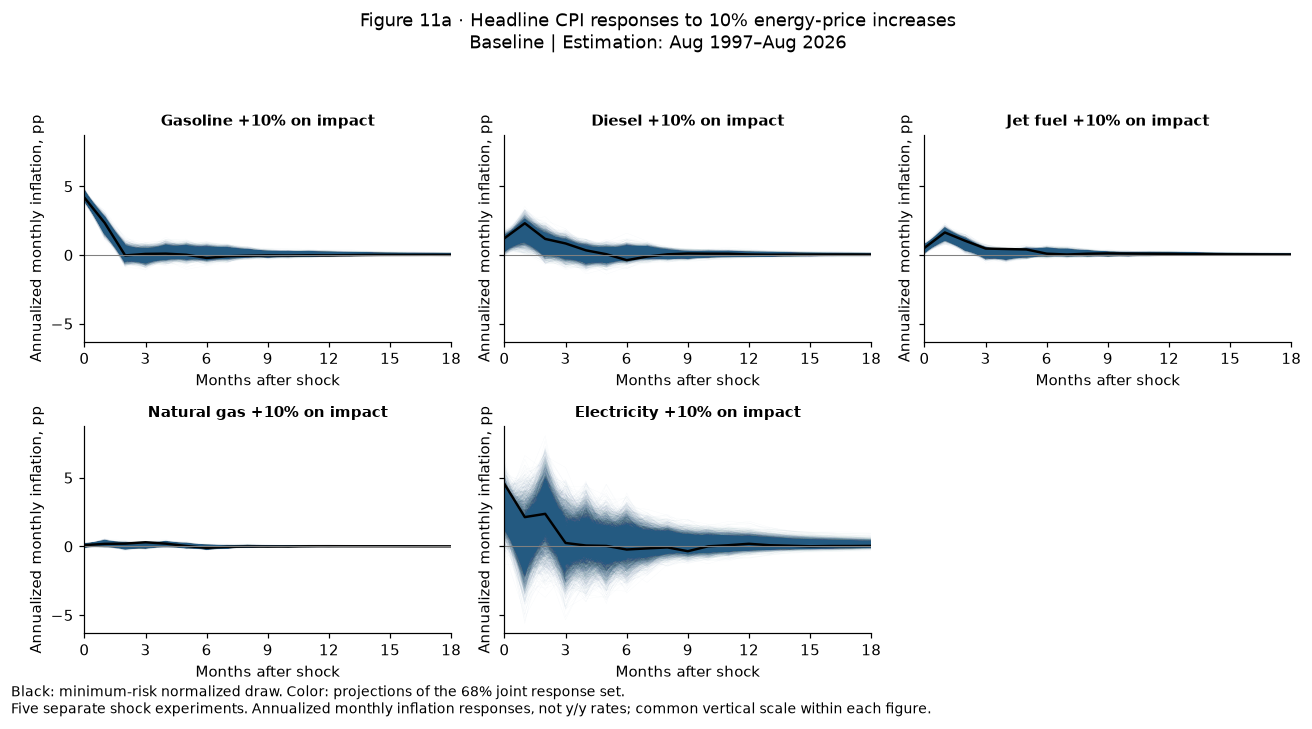

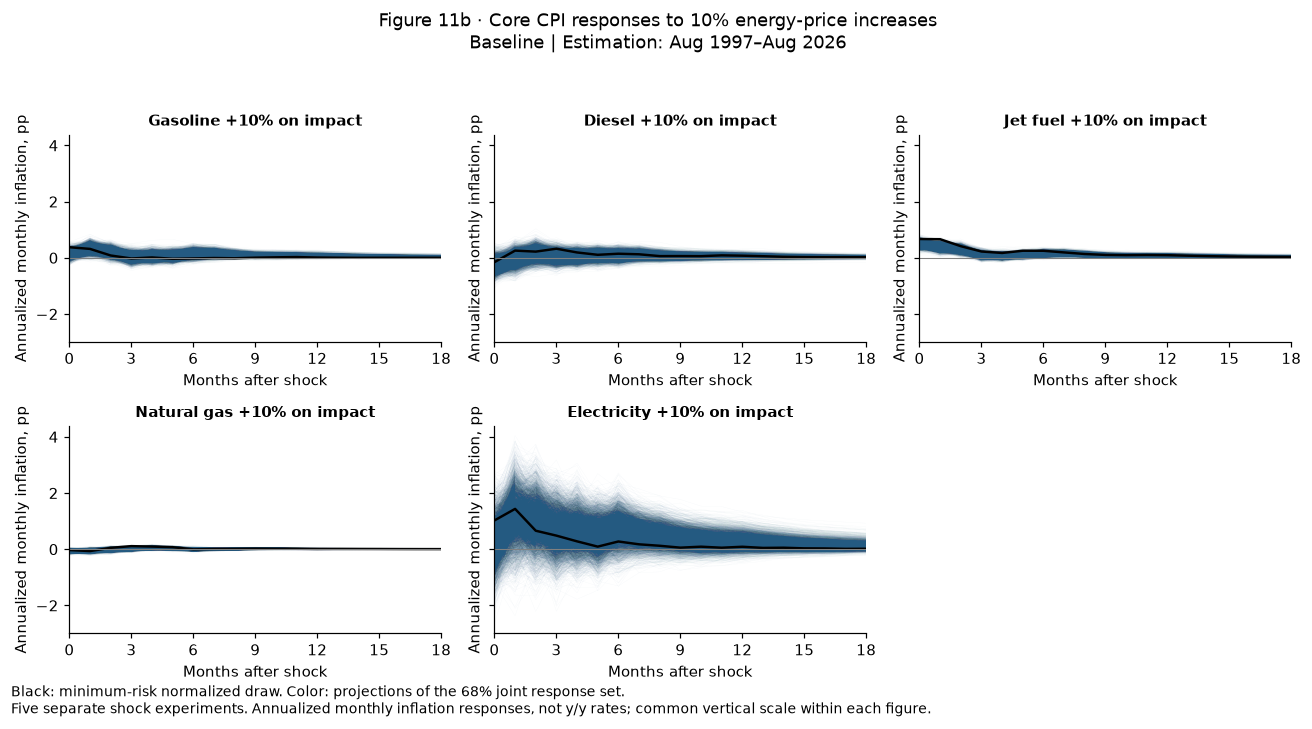

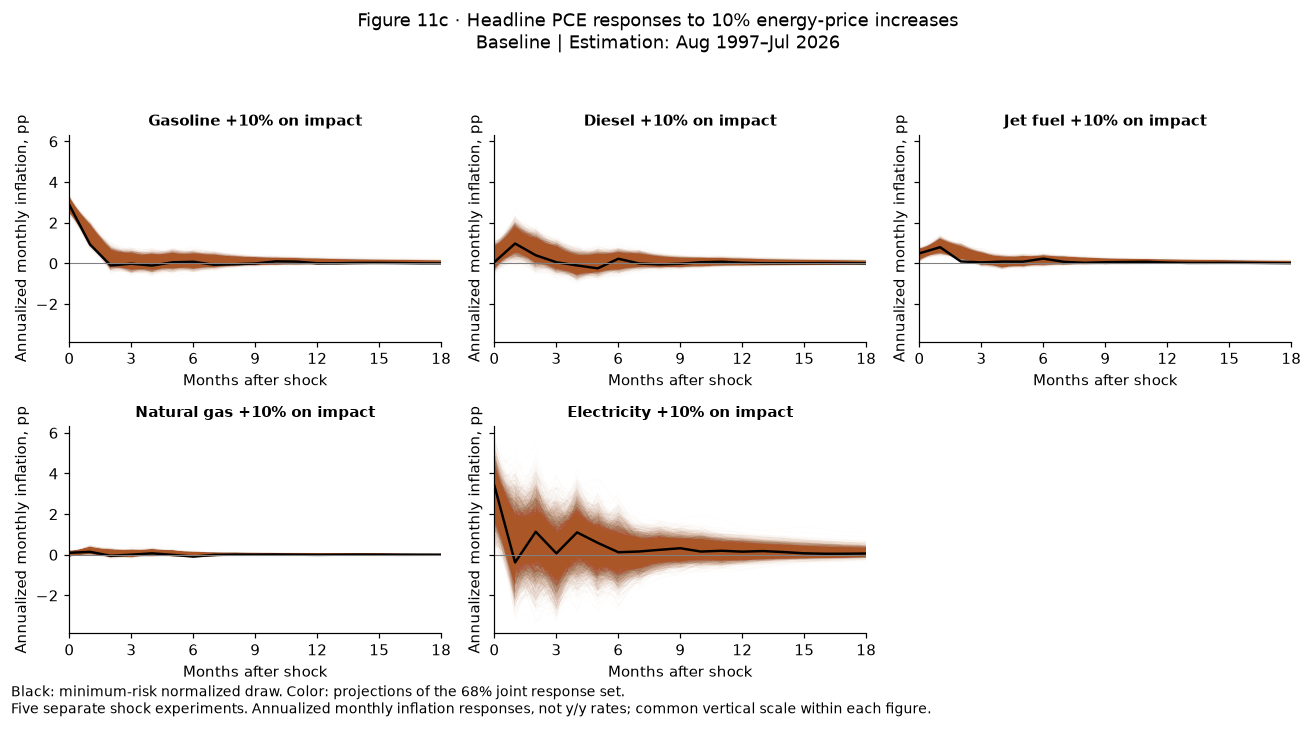

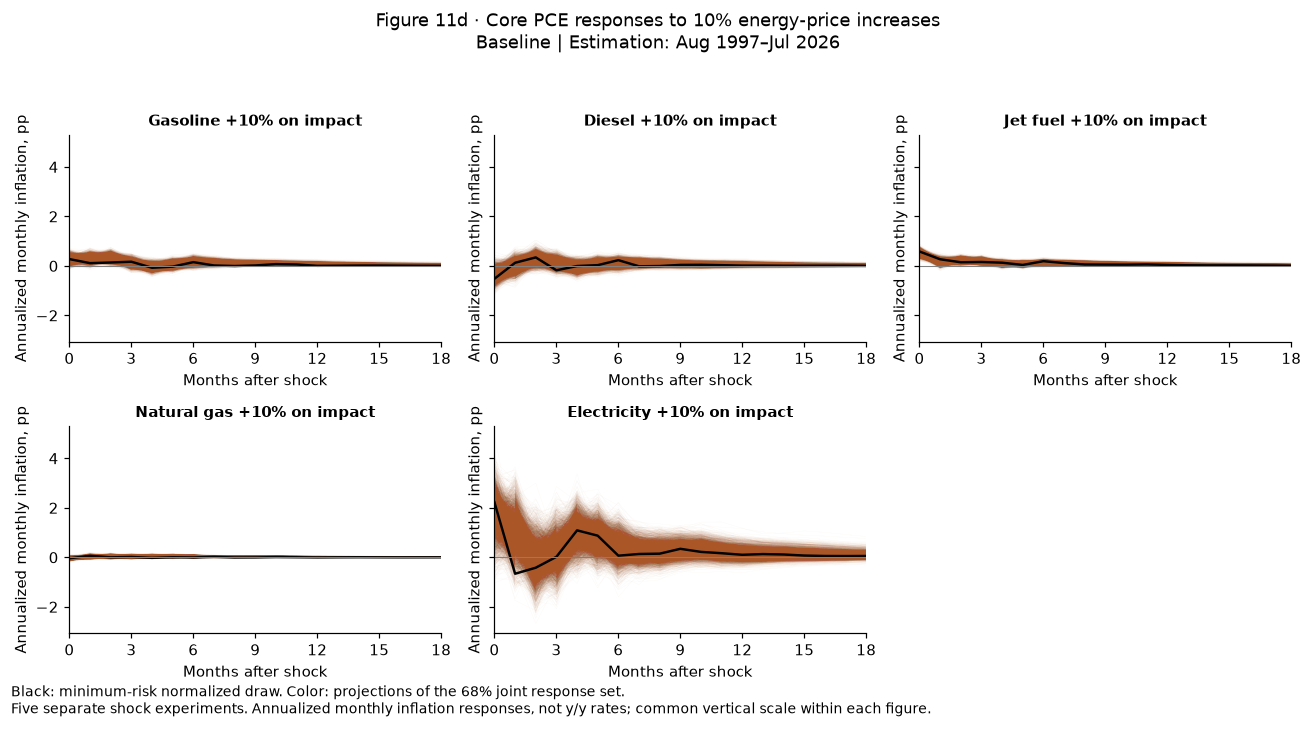

### Baseline: selected responses at selected horizons
Separate +10% initial price increases; annualized monthly inflation, percentage points. Tables show the jointly selected normalized draw; figures show joint posterior uncertainty.

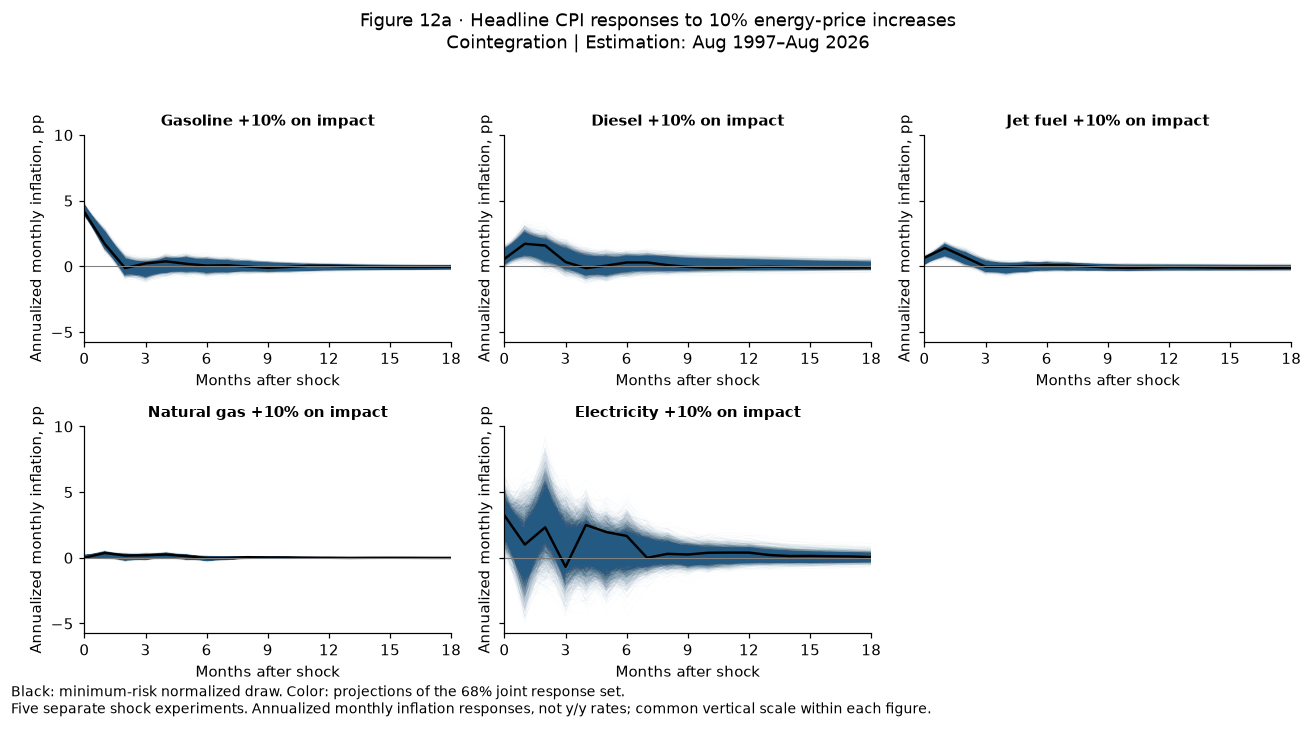

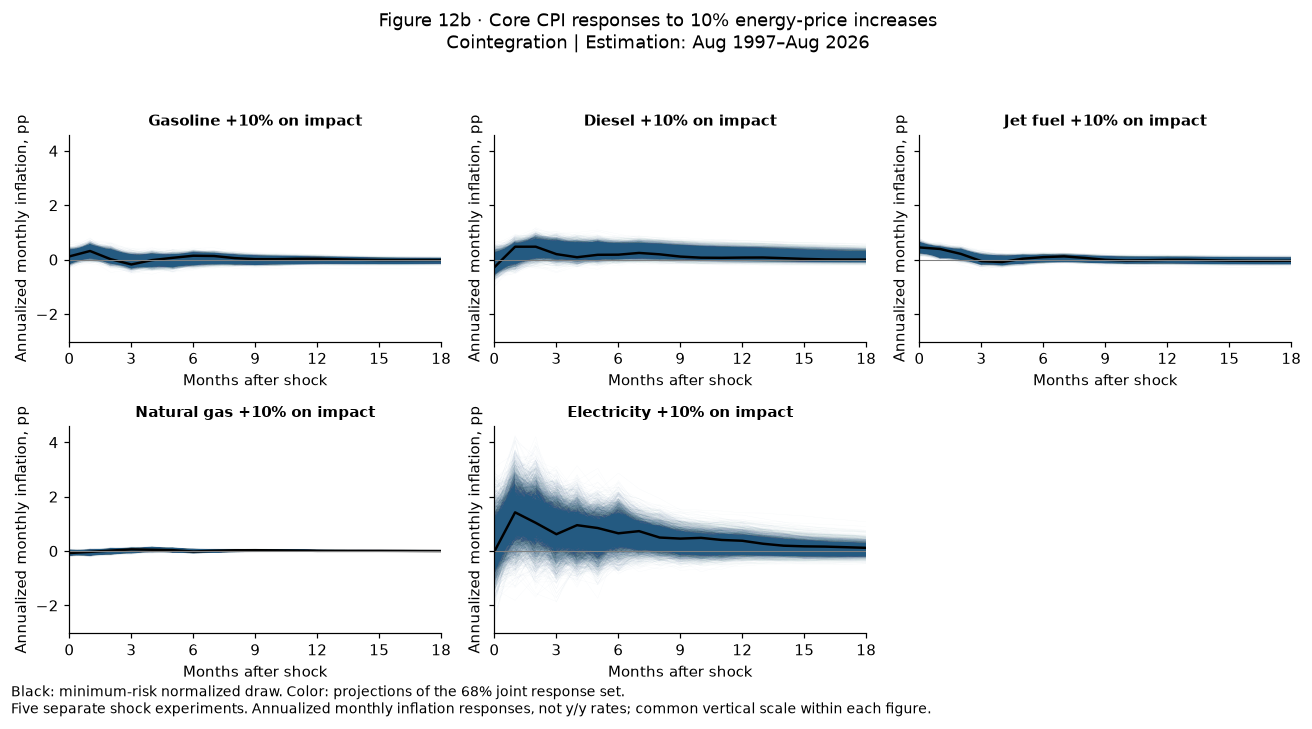

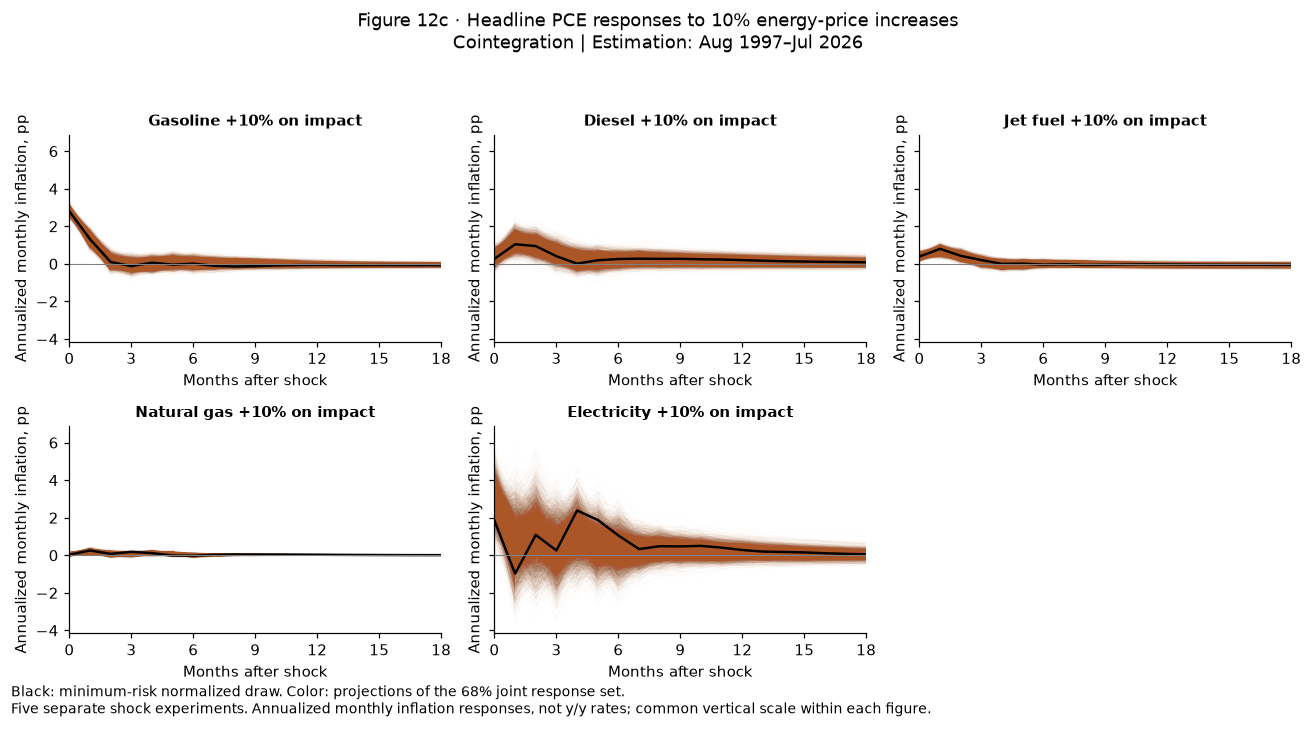

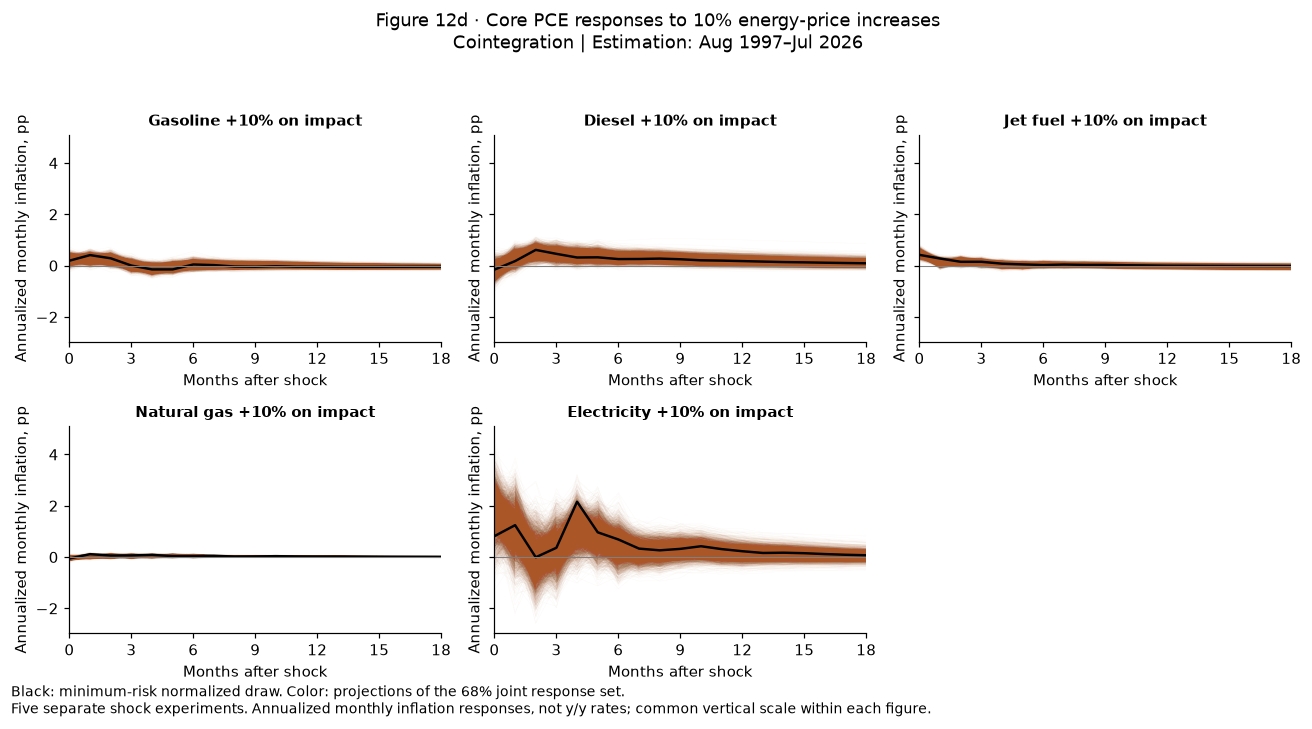

### Cointegration: selected responses at selected horizons
Separate +10% initial price increases; annualized monthly inflation, percentage points. Tables show the jointly selected normalized draw; figures show joint posterior uncertainty.

In [21]:
normalized_price_results, normalization_rows = {}, []
for (specification, measure), original in results.items():
    normalized, scales = fixed_price_irfs(original["irfs"], specification)
    point, joint_set, _ = joint_summary(normalized)
    assert normalized.shape == (DRAWS, IRF_HORIZON+1, 7, 5)
    assert len(joint_set) == int(np.ceil(CREDIBLE_MASS * DRAWS))
    normalized_price_results[(specification, measure)] = {
        "irfs": normalized, "point": point, "joint_set": joint_set}
    for shock, fuel in enumerate(ENERGY):
        normalization_rows.append({"Model": specification, "Measure": measure, "Shock": fuel,
            "Initial own-price increase (%)": PRICE_INCREASE_PCT,
            "Selected posterior draw": point, "Selected shock multiplier": scales[point, shock]})

display(Markdown("### Normalization audit\nMultipliers convert one-standard-deviation shocks "
    "to the chosen fuel-price increase within each posterior draw."))
display(pd.DataFrame(normalization_rows).style.format({
    "Initial own-price increase (%)": "{:.2f}", "Selected shock multiplier": "{:.4f}"}))

fixed_price_response_tables = {}
for specification, number in [("Baseline", 11), ("Cointegration", 12)]:
    rows = []
    for measure in ["CPI", "PCE"]:
        normalized = normalized_price_results[(specification, measure)]
        original = results[(specification, measure)]
        for variable in [0, 1]:
            letter = "abcd"[2*["CPI", "PCE"].index(measure) + variable]
            plot_fixed_price_irfs(normalized, original, measure, specification, f"{number}{letter}", variable)
        point_irfs = 12 * normalized["irfs"][normalized["point"], :, -2:, :]
        for variable, kind in enumerate(["Headline", "Core"]):
            for shock, fuel in enumerate(ENERGY):
                rows.append({"Inflation": f"{kind} {measure}", "Shock": fuel,
                    **{f"Month {h}": point_irfs[h, variable, shock] for h in [0, 1, 3, 6, 12, 18]}})
    table = pd.DataFrame(rows).set_index(["Inflation", "Shock"])
    fixed_price_response_tables[specification] = table
    display(Markdown(f"### {specification}: selected responses at selected horizons\n"
        f"Separate +{PRICE_INCREASE_PCT:g}% initial price increases; annualized monthly inflation, percentage points. "
        "Tables show the jointly selected normalized draw; figures show joint posterior uncertainty."))
    display(table.style.format("{:+.3f}"))


## 11. Projecting the March–July energy contribution through December 2026

**Question:** How large could the contribution of the **five energy shocks dated March–July 2026** to core PCE year-over-year inflation become by December? This extends Section 9's historical attribution; the future dates are conditional projections, not observations.

1. Recover the March–July energy shocks separately for every accepted PCE posterior draw, as in Section 9. Their seven-variable contribution is zero before March; earlier shocks remain in the counterfactual.
2. Carry the retained shocks' effects through December using that draw's VAR coefficients. After July, the contribution vector follows $d_t=\sum_{\ell=1}^{6}A_\ell d_{t-\ell}$: no further shocks or intercept enter this difference between paths.
3. Project two paths from July: one retaining the episode and one removing its effects from **both the lagged observations and the July core PCE price level**. The intercept and all earlier contributions remain in both paths. Set **all seven new innovations to zero after July**. Energy prices can still change endogenously; they are not held constant.
4. Integrate monthly core log inflation into price indexes, then calculate the difference between the two conventional y/y rates. All prior-year denominators are observed 2025 core PCE indexes and precede the episode, so they are unaffected.

If $c_t$ is the monthly core contribution in $100\Delta\log P_t$ units and $C_t=\sum_{s=March}^{t}c_s$, then

$$P_t^{without}=P_t^{with}\exp(-C_t/100),\qquad
Contribution_t^{yy}=100\frac{P_t^{with}}{P_{t-12}}\left[1-\exp(-C_t/100)\right].$$

Use observed $P_t$ through July and the model's conditional projected index thereafter. These are **percentage points of y/y inflation**. Do not multiply the contribution by 12: monthly log effects are accumulated into the price level, not annualized. The projected index follows the no-new-innovation log path; it is not the mean of a simulated future price-index distribution.

**Point estimates and uncertainty.** The selected line uses the same minimum-risk **historical** draw as Section 9, preserving its July attribution. The chart also shows posterior medians and **pointwise 68% intervals** (16th–84th percentiles); these are distinct from the joint response sets in the IRF figures. The selected historical draw need not lie within a particular scalar interval. To summarize the July–December peak, take each draw's maximum over those months first, then calculate the median and 95th percentile of the resulting 10,000 maxima. This gives a **one-sided 95% posterior upper bound for the peak**, not a finite worst-case maximum or the maximum of the monthly medians.

**Scope and dates.** This is the continuing effect of the existing March–July episode, not a scenario with additional energy shocks after July. Uncertainty reflects the posterior parameters and inferred historical shocks conditional on the maintained model; future innovations are not simulated. The forecast conditioning date stays fixed at July 2026. Parameters are taken from the notebook's PCE models, whose actual estimation endpoint is displayed below. A later rerun may use revised data and a longer estimation sample, so this is not a real-time July-vintage backtest. Baseline remains the primary specification and cointegration the sensitivity check.


In [22]:
def project_energy_contribution(frame, result, price_index, shock_start, origin, end):
    """Project a dated energy episode with zero new innovations after the origin."""
    shock_start, origin, end = map(pd.Timestamp, [shock_start, origin, end])
    if not shock_start <= origin < end or origin not in frame.index:
        raise ValueError("Use a valid observed origin and a later projection end.")
    if end - pd.DateOffset(years=1) >= shock_start:
        raise ValueError("This episode projection requires unaffected prior-year denominators.")
    historical_dates, historical_effects = energy_window_effects(
        frame, result, shock_start, origin, origin)
    b, impact = result["coefficients"], result["impacts"]
    draws, n = len(b), frame.shape[1]
    p = (b.shape[1]-1)//n
    a = unpack_coefficients(b, p, n)
    observed = frame.loc[:origin]
    future_dates = pd.date_range(origin + pd.offsets.MonthBegin(), end, freq="MS")
    dates = historical_dates.append(future_dates)

    # A shock's contribution has no intercept and is zero before the episode starts.
    effect_buffer = np.zeros((p, draws, n))
    for lag in range(min(p, len(historical_dates))):
        effect_buffer[lag] = historical_effects[:, -1-lag]
    with_buffer = np.stack([np.broadcast_to(observed.iloc[-1-lag].to_numpy(),
        (draws, n)).copy() for lag in range(p)])
    without_buffer = with_buffer - effect_buffer
    future_effects, with_rates, without_rates = [], [], []
    for date in future_dates:
        effect = np.zeros((draws, n))
        with_rate, without_rate = b[:, 0].copy(), b[:, 0].copy()
        for lag in range(p):
            effect += np.einsum("dij,dj->di", a[:, lag], effect_buffer[lag])
            with_rate += np.einsum("dij,dj->di", a[:, lag], with_buffer[lag])
            without_rate += np.einsum("dij,dj->di", a[:, lag], without_buffer[lag])
        np.testing.assert_allclose(with_rate - without_rate, effect, atol=1e-10)
        future_effects.append(effect)
        with_rates.append(with_rate)
        without_rates.append(without_rate)
        for buffer, current in [(effect_buffer, effect), (with_buffer, with_rate),
                                (without_buffer, without_rate)]:
            buffer[1:] = buffer[:-1].copy()
            buffer[0] = current
    effects = np.concatenate([historical_effects, np.stack(future_effects, axis=1)], axis=1)
    cumulative = effects[:, :, -1].cumsum(axis=1)  # Unannualized log percentage points.

    # Independent IRF convolution checks the historical and projected effect recursion.
    x, target = lagged_design(frame.to_numpy(), p)
    fitted_dates = frame.index[p:]
    selected = (fitted_dates >= shock_start) & (fitted_dates <= origin)
    residuals = target[selected][None] - x[selected][None] @ b
    shocks = np.linalg.solve(impact, residuals.swapaxes(1, 2)).swapaxes(1, 2)
    responses = impulse_responses(a, impact, len(dates)-1)
    convolution = np.zeros_like(effects)
    for t in range(len(dates)):
        for shock_t in range(min(t+1, len(historical_dates))):
            convolution[:, t] += np.einsum("dij,dj->di",
                responses[:, t-shock_t, :, :5], shocks[:, shock_t, :5])
    np.testing.assert_allclose(effects, convolution, atol=1e-10)

    # Observed indexes through the origin; conditional log-path forecasts thereafter.
    observed_index = price_index.reindex(historical_dates).to_numpy()
    prior_index = price_index.reindex(dates-pd.DateOffset(years=1)).to_numpy()
    if not (np.isfinite(observed_index).all() and np.isfinite(prior_index).all()
            and (observed_index > 0).all() and (prior_index > 0).all()):
        raise ValueError("Positive current and prior-year index observations are required.")
    with_rates = np.stack(with_rates, axis=1)
    without_rates = np.stack(without_rates, axis=1)
    future_index = observed_index[-1]*np.exp(with_rates[:, :, -1].cumsum(axis=1)/100)
    with_index = np.concatenate([np.broadcast_to(observed_index, (draws, len(observed_index))),
                                 future_index], axis=1)
    without_index = with_index*np.exp(-cumulative/100)
    # Independently integrate the paired counterfactual forecast from its adjusted origin.
    origin_without = observed_index[-1]*np.exp(-cumulative[:, len(historical_dates)-1]/100)
    independent_without = origin_without[:, None]*np.exp(without_rates[:, :, -1].cumsum(axis=1)/100)
    np.testing.assert_allclose(independent_without, without_index[:, len(historical_dates):], atol=1e-10)
    gross = with_index/prior_index[None]
    with_yoy = 100*(gross-1)
    without_yoy = 100*(without_index/prior_index[None]-1)
    contribution = -100*gross*np.expm1(-cumulative/100)
    np.testing.assert_allclose(with_yoy-without_yoy, contribution, atol=1e-10)
    return {"dates": dates, "contribution": contribution, "with_yoy": with_yoy,
        "without_yoy": without_yoy, "monthly_effect": effects[:, :, -1],
        "cumulative_log_effect": cumulative, "point": result["best_hd"]}


def check_zero_energy_projection():
    """Non-energy innovations alone must produce zero attributed energy contribution."""
    rng = np.random.default_rng(202612)
    toy_dates = pd.date_range("2022-01-01", "2026-07-01", freq="MS")
    a = np.stack([0.25*np.eye(7), 0.10*np.eye(7)])
    a[0, -1, 0] = 0.2  # Energy could transmit to core if an energy shock occurred.
    b = np.vstack([np.full((1, 7), 0.03), a[0].T, a[1].T])
    y = np.zeros((len(toy_dates), 7))
    for t in range(2, len(y)):
        y[t] = b[0] + a[0]@y[t-1] + a[1]@y[t-2]
        y[t, -2:] += rng.normal(scale=0.1, size=2)
    frame = pd.DataFrame(y, index=toy_dates)
    index = pd.Series(100*np.exp(np.cumsum(y[:, -1])/100), index=toy_dates)
    result = {"coefficients": b[None], "impacts": np.eye(7)[None], "best_hd": 0}
    projected = project_energy_contribution(frame, result, index,
        "2026-03-01", "2026-07-01", "2026-12-01")
    np.testing.assert_allclose(projected["contribution"], 0, atol=1e-10)


check_zero_energy_projection()
display(Markdown("**Passed:** synthetic zero-energy projection. Each full projection below also checks "
    "IRF convolution, paired forecast recursions, independently integrated price indexes, and exact y/y subtraction."))


**Passed:** synthetic zero-energy projection. Each full projection below also checks IRF convolution, paired forecast recursions, independently integrated price indexes, and exact y/y subtraction.

### Baseline: contribution to core PCE y/y inflation
Parameters estimated through **July 2026**; forecast conditioning history ends **July 2026**. Selected historical draw: **282**.

,Stage,Selected draw (pp),Posterior median (pp),68% lower (pp),68% upper (pp)
Month,,,,,
Mar 2026,Historical estimate,-0.010,0.010,-0.026,0.048
Apr 2026,Historical estimate,0.030,0.075,0.017,0.136
May 2026,Historical estimate,0.190,0.202,0.126,0.281
Jun 2026,Historical estimate,0.191,0.195,0.108,0.286
Jul 2026,Historical estimate,0.170,0.181,0.079,0.286
Aug 2026,Projection,0.147,0.177,0.063,0.295
Sep 2026,Projection,0.215,0.221,0.092,0.353
Oct 2026,Projection,0.250,0.255,0.114,0.399
Nov 2026,Projection,0.262,0.260,0.109,0.416


**December calculation:** 3.156622% y/y with the episode minus 2.895198% without it = **0.261424 pp**. The cumulative unannualized log price effect is 0.253746 pp.

### Cointegration: contribution to core PCE y/y inflation
Parameters estimated through **July 2026**; forecast conditioning history ends **July 2026**. Selected historical draw: **6871**.

,Stage,Selected draw (pp),Posterior median (pp),68% lower (pp),68% upper (pp)
Month,,,,,
Mar 2026,Historical estimate,0.006,0.030,-0.008,0.067
Apr 2026,Historical estimate,0.069,0.117,0.058,0.179
May 2026,Historical estimate,0.184,0.251,0.174,0.331
Jun 2026,Historical estimate,0.209,0.275,0.185,0.367
Jul 2026,Historical estimate,0.169,0.301,0.193,0.408
Aug 2026,Projection,0.166,0.325,0.204,0.447
Sep 2026,Projection,0.198,0.377,0.244,0.512
Oct 2026,Projection,0.248,0.411,0.267,0.559
Nov 2026,Projection,0.250,0.430,0.276,0.590


**December calculation:** 3.302615% y/y with the episode minus 3.025839% without it = **0.276776 pp**. The cumulative unannualized log price effect is 0.268287 pp.

### Peak contribution, July–December 2026
The 95% upper bound is the 95th posterior percentile of each draw's maximum over these months. It is not a hard ceiling and does not include additional future shocks.

,Selected peak (pp),Selected peak month,Median of peaks (pp),95% upper bound for peak (pp),December selected (pp)
Model,,,,,
Baseline,0.262,Nov 2026,0.269,0.533,0.261
Cointegration,0.277,Dec 2026,0.445,0.730,0.277


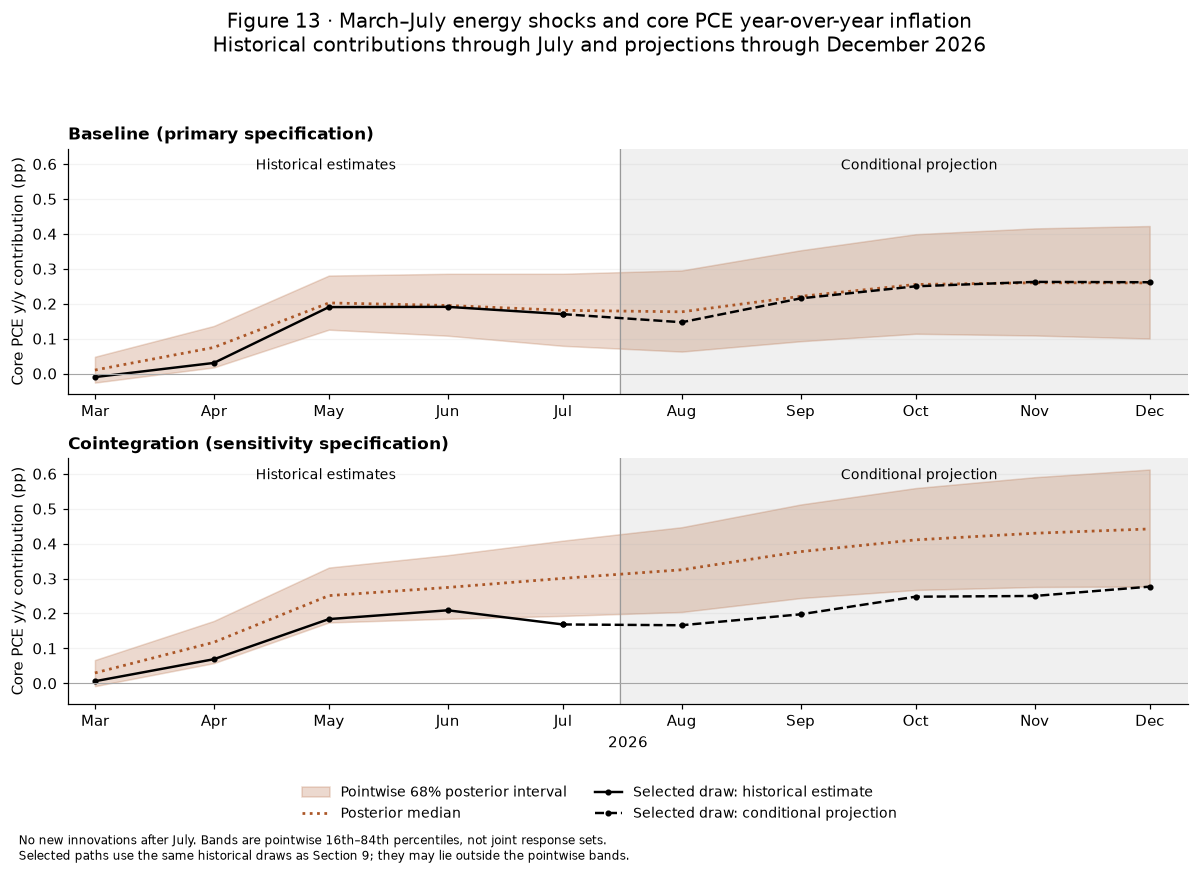

In [23]:
PROJECTION_ORIGIN = pd.Timestamp("2026-07-01")
PROJECTION_END = pd.Timestamp("2026-12-01")
assert PROJECTION_ORIGIN == SHOCK_END == YOY_MONTH
projection_results, projection_tables, projection_peak_rows = {}, {}, []
for specification in ["Baseline", "Cointegration"]:
    result = results[(specification, "PCE")]
    projected = project_energy_contribution(models[(specification, "PCE")], result,
        levels["Core PCE"], SHOCK_START, PROJECTION_ORIGIN, PROJECTION_END)
    projection_results[specification] = projected
    dates, contributions, point = projected["dates"], projected["contribution"], projected["point"]
    origin_position = dates.get_loc(PROJECTION_ORIGIN)
    np.testing.assert_allclose(contributions[point, origin_position],
        yoy_summary.loc[specification, "Selected-draw contribution (pp)"], atol=1e-10)
    q16, median, q84 = np.quantile(contributions, [0.16, 0.5, 0.84], axis=0)
    table = pd.DataFrame({
        "Stage": np.where(dates <= PROJECTION_ORIGIN, "Historical estimate", "Projection"),
        "Selected draw (pp)": contributions[point], "Posterior median (pp)": median,
        "68% lower (pp)": q16, "68% upper (pp)": q84}, index=dates.strftime("%b %Y"))
    table.index.name = "Month"
    projection_tables[specification] = table
    display(Markdown(f"### {specification}: contribution to core PCE y/y inflation\n"
        f"Parameters estimated through **{result['end']:%B %Y}**; forecast conditioning history ends "
        f"**{PROJECTION_ORIGIN:%B %Y}**. Selected historical draw: **{point}**."))
    display(table.style.format({column: "{:.3f}" for column in table.columns if column != "Stage"}))

    # Take the maximum within each draw first, then summarize that scalar distribution.
    peak_mask = dates >= PROJECTION_ORIGIN
    peaks = contributions[:, peak_mask].max(axis=1)
    peak_month = dates[peak_mask][contributions[point, peak_mask].argmax()]
    projection_peak_rows.append({"Model": specification,
        "Selected peak (pp)": peaks[point], "Selected peak month": peak_month.strftime("%b %Y"),
        "Median of peaks (pp)": np.median(peaks), "95% upper bound for peak (pp)": np.quantile(peaks, 0.95),
        "December selected (pp)": contributions[point, -1]})
    display(Markdown(f"**December calculation:** {projected['with_yoy'][point,-1]:.6f}% y/y with the episode "
        f"minus {projected['without_yoy'][point,-1]:.6f}% without it = **{contributions[point,-1]:.6f} pp**. "
        f"The cumulative unannualized log price effect is {projected['cumulative_log_effect'][point,-1]:.6f} pp."))

projection_peak_summary = pd.DataFrame(projection_peak_rows).set_index("Model")
display(Markdown(f"### Peak contribution, {PROJECTION_ORIGIN:%B}–{PROJECTION_END:%B %Y}\n"
    "The 95% upper bound is the 95th posterior percentile of each draw's maximum over these months. "
    "It is not a hard ceiling and does not include additional future shocks."))
display(projection_peak_summary.style.format({column: "{:.3f}" for column in projection_peak_summary.columns
    if column != "Selected peak month"}))

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, specification in zip(axes, ["Baseline", "Cointegration"]):
    projected = projection_results[specification]
    dates, values, point = projected["dates"], projected["contribution"], projected["point"]
    q16, median, q84 = np.quantile(values, [0.16, 0.5, 0.84], axis=0)
    historical, future = dates <= PROJECTION_ORIGIN, dates >= PROJECTION_ORIGIN
    boundary = PROJECTION_ORIGIN + pd.Timedelta(days=15)
    ax.axvspan(boundary, dates[-1]+pd.Timedelta(days=10), color="0.94", zorder=0)
    ax.axvline(boundary, color="0.6", linewidth=0.8)
    ax.fill_between(dates, q16, q84, color=COLORS["PCE"], alpha=0.22,
        label="Pointwise 68% posterior interval")
    ax.plot(dates, median, color=COLORS["PCE"], linestyle=":", linewidth=1.8, label="Posterior median")
    ax.plot(dates[historical], values[point, historical], color="black", marker="o", markersize=3,
        linewidth=1.6, label="Selected draw: historical estimate")
    ax.plot(dates[future], values[point, future], color="black", marker="o", markersize=3,
        linewidth=1.6, linestyle="--", label="Selected draw: conditional projection")
    ax.axhline(0, color="0.65", linewidth=0.7)
    ax.set_title(specification + (" (primary specification)" if specification == "Baseline" else " (sensitivity specification)"),
        loc="left", fontsize=11)
    ax.text(0.23, 0.96, "Historical estimates", transform=ax.transAxes, ha="center", va="top", fontsize=9)
    ax.text(0.76, 0.96, "Conditional projection", transform=ax.transAxes, ha="center", va="top", fontsize=9)
    ax.set_ylabel("Core PCE y/y contribution (pp)")
    ax.set_xlim(dates[0]-pd.Timedelta(days=7), dates[-1]+pd.Timedelta(days=10))
    ax.set_xticks(dates)
    ax.set_xticklabels(dates.strftime("%b"))
    ax.tick_params(labelbottom=True)
    ax.grid(axis="y", alpha=0.15)
axes[-1].set_xlabel("2026")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.045), ncol=2, frameon=False, fontsize=9)
fig.suptitle("Figure 13 · March–July energy shocks and core PCE year-over-year inflation\n"
    "Historical contributions through July and projections through December 2026", fontsize=13)
fig.text(0.02, 0.015, "No new innovations after July. Bands are pointwise 16th–84th percentiles, not joint response sets.\n"
    "Selected paths use the same historical draws as Section 9; they may lie outside the pointwise bands.", fontsize=8)
fig.tight_layout(rect=(0, 0.12, 1, 0.94))
plt.show()


In [24]:
diagnostics = pd.DataFrame({f"{s} / {m}": r["diagnostics"] for (s,m),r in results.items()}).T
display(Markdown("### Final diagnostics"))
display(diagnostics)
assert len(results) == 4 and all(r["diagnostics"]["Draws"] == DRAWS for r in results.values())
assert all(r["diagnostics"]["Reconstruction max error"] < 1e-6 for r in results.values())
assert all(len(r["set_irf"]) == int(np.ceil(CREDIBLE_MASS*DRAWS)) for r in results.values())
assert all(len(r["set_hd"]) == int(np.ceil(CREDIBLE_MASS*DRAWS)) for r in results.values())

# A split-draw check measures Monte Carlo sensitivity of variance-table medians.
mc_rows = []
for (s, m), r in results.items():
    delta = np.abs(np.median(r["fevd"][::2], axis=0)-np.median(r["fevd"][1::2], axis=0))
    mc_rows.append({"Model": s, "Measure": m, "Largest split-half median difference (pp)": delta.max()})
display(pd.DataFrame(mc_rows).round(3))
display(Markdown("**Completed:** four fitted systems, Figures 1–10 with CPI/PCE counterparts, Tables 2–3, "
    "Figures 11–12 for 10% energy-price increases, Figure 13 for the y/y projection, and all accounting checks. Joint estimates and set boundaries remain Monte Carlo approximations; "
    "increase DRAWS for finer numerical precision. Data revisions can also change results on rerun."))

### Final diagnostics

,Draws,Rejected unstable,Acceptance %,Estimation start,Endpoint,Observations,Largest retained root,Reconstruction max error,Seed,Seconds
Baseline / CPI,10000,0,100.0,1997-08-01 00:00:00,2026-08-01 00:00:00,349,0.965667,0.0,2224,66.99098
Baseline / PCE,10000,0,100.0,1997-08-01 00:00:00,2026-07-01 00:00:00,348,0.975626,0.0,2225,68.727312
Cointegration / CPI,10000,37,99.631364,1997-08-01 00:00:00,2026-08-01 00:00:00,349,0.999528,0.0,2226,66.2905
Cointegration / PCE,10000,21,99.79044,1997-08-01 00:00:00,2026-07-01 00:00:00,348,0.999581,0.0,2227,45.980671


,Model,Measure,Largest split-half median difference (pp)
0,Baseline,CPI,0.173
1,Baseline,PCE,0.229
2,Cointegration,CPI,0.099
3,Cointegration,PCE,0.083


**Completed:** four fitted systems, Figures 1–10 with CPI/PCE counterparts, Tables 2–3, Figures 11–12 for 10% energy-price increases, Figure 13 for the y/y projection, and all accounting checks. Joint estimates and set boundaries remain Monte Carlo approximations; increase DRAWS for finer numerical precision. Data revisions can also change results on rerun.

### What the exercise can and cannot establish

- Energy contributions are model-based departures from counterfactual paths under recursive identification. The remaining contribution is not separately identified as demand, supply chains, wages, or monetary policy.
- A positive energy contribution raises the current inflation rate; a negative contribution lowers it. A large share of long-run variance does not imply that energy accounts for the same share of the latest inflation level.
- Core responses measure effects on an index excluding food and energy. They can include indirect transmission through transport and production costs, but the model does not separately identify those mechanisms.
- Full-sample spot prices, household electricity, and weekly-to-monthly diesel aggregation change measurement relative to v1 and the paper. There are no spot continuations. STL uses the full estimation sample for each model. Four October 2025 series are eligible for geometric interpolation. Measurement, seasonal-adjustment, and interpolation uncertainty are not included in posterior bands.
- The transformed sample begins in February 1997 rather than February 1995. CPI and PCE normally use different latest endpoints; comparisons reflect that sample difference as well as their index definitions. FRED's household electricity measure is not the paper's all-sector price.
- Constant coefficients, six lags, Gaussian innovations, the prior, and stability conditioning are maintained assumptions. This notebook does not estimate time-varying parameters, pandemic-specific volatility, alternative lags, or a combined CPI/PCE model.

### References

1. Kilian, L., and X. Zhou (2022). [A Broader Perspective on the Inflationary Effects of Energy Price Shocks](https://www.dallasfed.org/~/media/documents/research/papers/2022/wp2224.pdf). Dallas Fed Working Paper 2224, especially sections 3–5 and Figures 1–10/Tables 2–3.
2. Inoue, A., and L. Kilian (2022). [Joint Bayesian inference about impulse responses in VAR models](https://doi.org/10.1016/j.jeconom.2021.05.010). _Journal of Econometrics_, 231, 457–476. [Author's method-code page](https://sites.google.com/site/lkilian2019/research/code).
3. [SciPy inverse-Wishart](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.invwishart.html), [matrix-normal distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.matrix_normal.html), and [discrete Lyapunov solver](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.solve_discrete_lyapunov.html).
4. [statsmodels STL](https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.STL.html) and [VAR](https://www.statsmodels.org/stable/vector_ar.html).
5. FRED series links are listed in section 2. All displayed results use the retrieval time and package versions printed in this notebook.